4.1 Sensitivity Analysis 
Conduct experiments to examine how changes in inputs and modelling choices affect 
forecasting performance. You must include at minimum: 
• Feature removal (ablation study): re-train the model with each of the 
following groups removed in turn: all three evaporation features; wind speed; 
rainfall. 
• Station removal: re-train with each station removed from the graph in turn 
and measure the impact on forecasting accuracy at the remaining stations.  
6 
Compare the feature-sensitivity findings with the correlation analysis conducted during 
data preparation in Part 1. Discuss cases where correlation analysis and model 
sensitivity provide different conclusions regarding feature importance and provide 
possible explanations for these differences. 

In [1]:
%pip install matplotlib numpy spektral tensorflow

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import os
os.environ["TF_USE_LEGACY_KERAS"] = "1"
import pandas as pd
import cv2
import numpy as np
from PIL import Image
import os
import tifffile as tiff

from skimage.transform import resize

import matplotlib.pyplot as plt

from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import ( 
    Flatten, 
    Conv2D, 

    MaxPooling2D, 
    Dense, 
    Dropout, 
)

In [3]:
import os
os.environ["TF_USE_LEGACY_KERAS"] = "1"
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt

from tensorflow.keras import Model
from tensorflow.keras.layers import Input, Dense, GRU, Dropout
from spektral.layers import GCNConv

import pickle
from pathlib import Path

In [4]:
station_FILE = "../data/raw/Station_geometry.csv"

# ── Task 1.1 — Load the LCDB shapefile ───────────────────────

station = pd.read_csv(station_FILE)

print("Shape:", station.shape)
station.head()

Shape: (5, 5)


,Station,Agent No.,Latitude,Longitude,Abbreviation
0,Christchurch Aero,4843,-43.493,172.537,CA
1,"Christchurch, Kyle St EWS",24120,-43.531,172.608,CK
2,ASHBURTON AERO AWS,26170,-43.903,171.804,AA
3,Rangiora EWS,17244,-43.329,172.611,RE
4,Hanmer Forest EWS,11234,-42.534,172.851,HF


In [5]:
import pandas as pd
import numpy as np
from sklearn.metrics.pairwise import haversine_distances

# Convert latitude and longitude from strings to numbers
station["Latitude"] = pd.to_numeric(station["Latitude"])
station["Longitude"] = pd.to_numeric(station["Longitude"])

# Combine coordinates and convert degrees to radians
coords = np.radians(
    station[["Latitude", "Longitude"]].to_numpy()
)

# Calculate the 10 unique pairwise distances
for i in range(len(station)):
    for j in range(i + 1, len(station)):
        result = haversine_distances([coords[i], coords[j]])
        distance_km = result[0, 1] * 6371

        print(
            f'{station.iloc[i]["Station"]} -- '
            f'{station.iloc[j]["Station"]}: '
            f'{distance_km:.2f} km'
        )

Christchurch Aero -- Christchurch, Kyle St EWS: 7.12 km
Christchurch Aero -- ASHBURTON AERO AWS: 74.50 km
Christchurch Aero -- Rangiora EWS: 19.19 km
Christchurch Aero -- Hanmer Forest EWS: 109.65 km
Christchurch, Kyle St EWS -- ASHBURTON AERO AWS: 76.72 km
Christchurch, Kyle St EWS -- Rangiora EWS: 22.46 km
Christchurch, Kyle St EWS -- Hanmer Forest EWS: 112.61 km
ASHBURTON AERO AWS -- Rangiora EWS: 91.07 km
ASHBURTON AERO AWS -- Hanmer Forest EWS: 174.27 km
Rangiora EWS -- Hanmer Forest EWS: 90.53 km


we can see the distance between the stations and from that, we can see that  Christchurch, Kyle St EWS (RK), Rangiora EWS (RE) and Christchurch Aero (CA) are closer to each other with the distance < 50 km>, I can say that their connection are 1. Mean while, ASHBURTON AERO AWS (AA) and Hanmer Forest EWS (HF) are far from each other and far from the three other nodes, so their connections to each other is 0 

The first one I will do is removing the attributes so I will keep the nodes the same 

In the next I create the nodes 

In [ ]:
# Step 1N
nodes = list(range(5))

print(nodes)

[0, 1, 2, 3, 4]


We will name CA: 0, CK:1, AA:2, RE:3, HF:4. In the next I identify assign the edges weight to the nodes 

In [ ]:
# Step 2N
edges = [
    (0, 1),
    (1, 0),

    (0, 3),
    (3, 0),

    (2, 3),
    (3, 2),

]

Then I create the adjacency matrix 

In [ ]:
# Step 3N
A = np.zeros((5, 5))

for i, j in edges:
    A[i, j] = 1

print(A)

[[0. 1. 0. 1. 0.]
 [1. 0. 0. 0. 0.]
 [0. 0. 0. 1. 0.]
 [1. 0. 1. 0. 0.]
 [0. 0. 0. 0. 0.]]


To get the node features, I choose to combine the latitude and logitude node with the weather dataset. So first I read the weather dataset again 

In [9]:
# Read the dataset
df_all = pd.read_csv('../data/clean/Pre-processed Data.csv')

First of all to make sure that we can match the matrix with the feature nodes data I must make sure that all the date in the weather dataset has the data of 5 nodes or station. So I will filter out the dates with the number of nodes less than 5. I calculate the number of nodes by date in this table below 

In [10]:
stations_per_date = (
    df_all.groupby("Observation time UTC_x", observed=True)["Station"]
    .nunique().reset_index(name="Count")
)
stations_per_date.name = "Station_Count"
print(stations_per_date.head(5))


      Observation time UTC_x  Count
0  2006-02-11 20:00:00+00:00      4
1  2006-02-12 20:00:00+00:00      4
2  2006-02-13 20:00:00+00:00      4
3  2006-02-14 20:00:00+00:00      4
4  2006-02-15 20:00:00+00:00      4


I check the data type of date column to make sure we can merge them back to the weather dataset 

In [11]:
stations_per_date.dtypes

Observation time UTC_x      str
Count                     int64
dtype: object

In [12]:
stations_per_date["Count"].unique()

array([4, 5, 3, 2, 1])

In [13]:
df_all.dtypes

Observation time UTC_x             str
evap_penman_open               float64
evap_penman_pet                float64
evap_priestley_taylor          float64
Rainfall [mm]                  float64
Speed [m/s]                    float64
Maximum Temperature [Deg C]    float64
Minimum Temperature [Deg C]    float64
Mean Temperature [Deg C]_x     float64
Target 7 day temperature       float64
Station                            str
dtype: object

In [14]:
df_all["Observation time UTC_x"]=pd.to_datetime(df_all["Observation time UTC_x"])

In [15]:
df_all.dtypes

Observation time UTC_x         datetime64[us, UTC]
evap_penman_open                           float64
evap_penman_pet                            float64
evap_priestley_taylor                      float64
Rainfall [mm]                              float64
Speed [m/s]                                float64
Maximum Temperature [Deg C]                float64
Minimum Temperature [Deg C]                float64
Mean Temperature [Deg C]_x                 float64
Target 7 day temperature                   float64
Station                                        str
dtype: object

To be safe for the merger I created the new column Date_Key in both two table with the same format 

In [16]:
df_all["Date_key"] = pd.to_datetime(
    df_all["Observation time UTC_x"], utc=True
).dt.strftime("%Y-%m-%d")

stations_per_date["Date_key"] = pd.to_datetime(
    stations_per_date["Observation time UTC_x"], utc=True
).dt.strftime("%Y-%m-%d")

In [17]:
df_all["Station"].unique()

<ArrowStringArray>
['AA', 'CA', 'RE', 'HF', 'CK']
Length: 5, dtype: str

Merge back to the df_all

In [18]:
df_all_count_station = pd.merge(df_all[["Date_key", "evap_penman_open",              
    "evap_penman_pet" ,              
    "evap_priestley_taylor",         
    "Rainfall [mm]",                  
    "Speed [m/s]",                  
    "Maximum Temperature [Deg C]",    
    "Minimum Temperature [Deg C]",       
    "Mean Temperature [Deg C]_x" , "Station"      
    ]],stations_per_date[["Date_key", "Count"]], on="Date_key", how="inner")

In [19]:
df_all_count_station.head(5)

,Date_key,evap_penman_open,evap_penman_pet,evap_priestley_taylor,Rainfall [mm],Speed [m/s],Maximum Temperature [Deg C],Minimum Temperature [Deg C],Mean Temperature [Deg C]_x,Station,Count
0,2006-02-11,6.5,5.5,4.0,0.0,3.01,26.7,14.5,20.6,AA,4
1,2006-02-12,8.6,6.3,4.2,0.0,3.17,29.3,12.5,20.9,AA,4
2,2006-02-13,4.5,4.3,3.4,0.0,4.10,20.6,10.3,15.5,AA,4
3,2006-02-14,2.9,2.3,1.7,0.4,2.34,22.5,6.2,14.4,AA,4
4,2006-02-15,2.0,3.3,3.5,0.0,3.10,19.7,5.8,12.8,AA,4


Then I filter out only the rows with count of station being 5

In [20]:
df_all_5 = df_all_count_station[df_all_count_station['Count']==5]
print(df_all_5.head(10))
df_all_5.shape

      Date_key  evap_penman_open  evap_penman_pet  evap_priestley_taylor  \
13  2006-02-24               4.2              4.2                    3.5   
20  2006-03-04               5.1              3.6                    1.7   
21  2006-03-05               3.5              3.4                    2.6   
22  2006-03-06               8.6              6.4                    3.2   
23  2006-03-07               2.2              1.8                    1.2   
24  2006-03-08               3.3              2.8                    2.0   
25  2006-03-09               2.7              3.1                    2.7   
26  2006-03-10               5.4              3.8                    1.8   
27  2006-03-18               5.5              3.7                    2.0   
28  2006-03-19               1.4              1.2                    0.9   

    Rainfall [mm]  Speed [m/s]  Maximum Temperature [Deg C]  \
13            0.0         2.14                         23.6   
20            0.0         2.65       

(26505, 11)

I assigned numbers to station so that I can arrange the rows later 

In [21]:


df_all_5["Station Order"] = 0

df_all_5.loc[df_all_5["Station"] == "CA", 'Station Order'] = 1
df_all_5.loc[df_all_5["Station"] == "CK", 'Station Order'] = 2
df_all_5.loc[df_all_5["Station"] == "AA", 'Station Order'] = 3
df_all_5.loc[df_all_5["Station"] == "RE", 'Station Order'] = 4
df_all_5.loc[df_all_5["Station"] == "HF", 'Station Order'] = 5




df_all_5.head()

,Date_key,evap_penman_open,evap_penman_pet,evap_priestley_taylor,Rainfall [mm],Speed [m/s],Maximum Temperature [Deg C],Minimum Temperature [Deg C],Mean Temperature [Deg C]_x,Station,Count,Station Order
13,2006-02-24,4.2,4.2,3.5,0.0,2.14,23.6,10.9,17.3,AA,5,3
20,2006-03-04,5.1,3.6,1.7,0.0,2.65,14.5,3.1,8.8,AA,5,3
21,2006-03-05,3.5,3.4,2.6,0.0,2.18,19.7,6.8,13.3,AA,5,3
22,2006-03-06,8.6,6.4,3.2,1.8,4.28,27.1,10.5,18.8,AA,5,3
23,2006-03-07,2.2,1.8,1.2,0.2,2.44,15.4,6.3,10.9,AA,5,3


In [22]:
df_all_5["Station Order"].dtype



dtype('int64')

In [23]:
df_all_5["Station Order"].unique()

array([3, 1, 4, 5, 2])

Then I sort the data by date first and then by station order 

In [24]:
# Sort by date (latest date first), then station order (1 to 5)
df_all_5 = df_all_5.sort_values(
    by=["Date_key", "Station Order"],
    ascending=[True, True]
).reset_index(drop=True)


In [167]:
print(df_all_5[["Date_key", "Station", "Station Order"]].head(10))

     Date_key Station  Station Order
0  2006-02-24      CA              1
1  2006-02-24      CK              2
2  2006-02-24      AA              3
3  2006-02-24      RE              4
4  2006-02-24      HF              5
5  2006-03-04      CA              1
6  2006-03-04      CK              2
7  2006-03-04      AA              3
8  2006-03-04      RE              4
9  2006-03-04      HF              5


In [25]:
df_all_5.dtypes

Date_key                           str
evap_penman_open               float64
evap_penman_pet                float64
evap_priestley_taylor          float64
Rainfall [mm]                  float64
Speed [m/s]                    float64
Maximum Temperature [Deg C]    float64
Minimum Temperature [Deg C]    float64
Mean Temperature [Deg C]_x     float64
Station                            str
Count                            int64
Station Order                    int64
dtype: object

So I have created a table for the note features with data arranged in the order of date first and the order of the station, the same order we have in the matrix A, which will allow me to run the model later on. 

First I will check some attributes of the matrix A

In [26]:
# Check the adjacency matrix
print("A shape:", A.shape)
print("A minimum:", A.min())
print("A maximum:", A.max())
print("Non-zero edges:", np.count_nonzero(A))

A shape: (5, 5)
A minimum: 0.0
A maximum: 1.0
Non-zero edges: 6


In [27]:
# Add self-loops:

A = A.astype(np.float32)

A_with_self_loops = A + np.eye(A.shape[0], dtype=np.float32)

print("Original non-zero values:",
      np.count_nonzero(A))

print("After adding self-loops:",
      np.count_nonzero(A_with_self_loops))

Original non-zero values: 6
After adding self-loops: 11


In the next I identify the columns for X and Y 

So I will create different feature_cols for removing different groups of attributes 

In [28]:
feature_cols = [
    "evap_penman_open",              
    "evap_penman_pet" ,              
    "evap_priestley_taylor",         
    "Rainfall [mm]",                  
    "Speed [m/s]",                  
    "Maximum Temperature [Deg C]",    
    "Minimum Temperature [Deg C]",       
    "Mean Temperature [Deg C]_x" ,       
    ]

In [29]:
target_col = [
           
    "Mean Temperature [Deg C]_x" ,       
    ]

In [30]:
feature_cols_evapo_remove_5 = [
             
    "Rainfall [mm]",                  
    "Speed [m/s]",                  
    "Maximum Temperature [Deg C]",    
    "Minimum Temperature [Deg C]",       
    "Mean Temperature [Deg C]_x" ,       
    ]

In [31]:
feature_cols_rain_remove_7 = [
    "evap_penman_open",              
    "evap_penman_pet" ,              
    "evap_priestley_taylor",                      
    "Speed [m/s]",                  
    "Maximum Temperature [Deg C]",    
    "Minimum Temperature [Deg C]",       
    "Mean Temperature [Deg C]_x" ,       
    ]

In [32]:
feature_cols_wind_remove_7 = [
    "evap_penman_open",              
    "evap_penman_pet" ,              
    "evap_priestley_taylor",                      
    "Rainfall [mm]",                  
    "Maximum Temperature [Deg C]",    
    "Minimum Temperature [Deg C]",       
    "Mean Temperature [Deg C]_x" ,       
    ]

In [33]:
df_all_5.head(10)

,Date_key,evap_penman_open,evap_penman_pet,evap_priestley_taylor,Rainfall [mm],Speed [m/s],Maximum Temperature [Deg C],Minimum Temperature [Deg C],Mean Temperature [Deg C]_x,Station,Count,Station Order
0,2006-02-24,3.6,4.0,3.6,0.0,2.79,22.5,7.0,14.8,CA,5,1
1,2006-02-24,4.1,4.0,3.5,0.0,2.14,22.3,9.9,16.1,CK,5,2
2,2006-02-24,4.2,4.2,3.5,0.0,2.14,23.6,10.9,17.3,AA,5,3
3,2006-02-24,3.1,3.7,3.6,0.0,1.81,21.6,7.0,14.3,RE,5,4
4,2006-02-24,3.1,3.6,3.5,0.0,1.61,24.5,4.4,14.5,HF,5,5
5,2006-03-04,2.4,2.2,1.5,1.6,3.75,13.4,3.5,8.5,CA,5,1
6,2006-03-04,2.3,2.0,1.5,3.2,2.65,13.5,4.1,8.8,CK,5,2
7,2006-03-04,5.1,3.6,1.7,0.0,2.65,14.5,3.1,8.8,AA,5,3
8,2006-03-04,2.5,2.4,1.8,1.8,3.87,13.3,3.1,8.2,RE,5,4
9,2006-03-04,2.6,1.7,0.9,0.2,1.48,14.2,-1.5,6.4,HF,5,5


I will assign x and y to the corresponding columns

First I will do with the removal of three evaporation attributes 

In [100]:
# Step 1_attribute
n_dates_eva = df_all_5["Date_key"].nunique()

X_eva = df_all_5[feature_cols_evapo_remove_5].to_numpy(dtype=np.float32)
y = df_all_5[target_col].to_numpy(dtype=np.float32)

X_eva = X_eva.reshape(n_dates_eva, 5, 5)
y = y.reshape(n_dates_eva, 5)

print("X:", X_eva.shape)
print("y:", y.shape)

X: (5301, 5, 5)
y: (5301, 5)


In [ ]:
# Step 1_attribute
n_dates_eva = df_all_5["Date_key"].nunique()

X_eva = df_all_5[feature_cols_evapo_remove_5].to_numpy(dtype=np.float32)
y = df_all_5[target_col].to_numpy(dtype=np.float32)

X_eva = X_eva.reshape(n_dates_eva, 5, 5)
y = y.reshape(n_dates_eva, 5)

print("X:", X_eva.shape)
print("y:", y.shape)

X: (5301, 5, 5)
y: (5301, 5)


In [101]:
#Step 2 attribute
# Normalize the traffic data
n = len(X_eva)

train_end = int(n * 0.70)
val_end = int(n * 0.85)

X_eva_train_data = X_eva[:train_end]
X_eva_val_data = X_eva[train_end:val_end]
X_eva_test_data = X_eva[val_end:]

y_train_data = y[:train_end]
y_val_data = y[train_end:val_end]
y_test_data = y[val_end:]

print("X_Train:", X_eva_train_data.shape)
print("X_Validation:", X_eva_val_data.shape)
print("X_Test:", X_eva_test_data.shape)

print("y_Train:", y_train_data.shape)
print("y_Validation:", y_val_data.shape)
print("y_Test:", y_test_data.shape)

X_Train: (3710, 5, 5)
X_Validation: (795, 5, 5)
X_Test: (796, 5, 5)
y_Train: (3710, 5)
y_Validation: (795, 5)
y_Test: (796, 5)


Then I scale the data 

In [102]:
# Step 3 attribute
from sklearn.preprocessing import StandardScaler

# Create scaler
scaler = StandardScaler()

# Fit only on training data
X_eva_train_data_scaled = scaler.fit_transform(X_eva_train_data.reshape(-1, 5)).reshape(X_eva_train_data.shape)
X_eva_val_data_scaled = scaler.transform(X_eva_val_data.reshape(-1, 5)).reshape(X_eva_val_data.shape)
X_eva_test_data_scaled = scaler.transform(X_eva_test_data.reshape(-1, 5)).reshape(X_eva_test_data.shape)


y_train_data_scaled = scaler.fit_transform(y_train_data.reshape(-1, 1)).reshape(y_train_data.shape)
y_val_data_scaled = scaler.transform(y_val_data.reshape(-1, 1)).reshape(y_val_data.shape)
y_test_data_scaled = scaler.transform(y_test_data.reshape(-1, 1)).reshape(y_test_data.shape)

Then  create the temporal sequences. 

In [103]:
#Step 4 A
# Create temporal sequences
LOOK_BACK = 12

def create_X_sequences(data, look_back=12):
    X = []
    

    for i in range(len(data) - look_back +1):
        X.append(data[i:i + look_back])
        

    return np.array(X)




def create_Y_sequences(data, look_back=12):
    
    y = []

    for i in range(len(data) - look_back +1):
        
        y.append(data[i + look_back-1])

    return np.array(y)

In [104]:
# Step 5 A

# Create train/validation/test sequences
X_eva_train = create_X_sequences(
    X_eva_train_data_scaled,
    LOOK_BACK
)

y_train = create_Y_sequences(
    y_train_data_scaled,
    LOOK_BACK
)

X_eva_val = create_X_sequences(
    X_eva_val_data_scaled,
    LOOK_BACK
)

y_val = create_Y_sequences(
    y_val_data_scaled,
    LOOK_BACK
)

X_eva_test = create_X_sequences(
    X_eva_test_data_scaled,
    LOOK_BACK
)

y_test = create_Y_sequences(
    y_test_data_scaled,
    LOOK_BACK
)

In [105]:
# Step 6
print("X_train:", X_eva_train.shape)
print("X_val:", X_eva_val.shape)
print("X_test:", X_eva_test.shape)

X_train: (3699, 12, 5, 5)
X_val: (784, 12, 5, 5)
X_test: (785, 12, 5, 5)


In [106]:
# Step 7
print("Y_train:", y_train.shape)
print("Y_val:", y_val.shape)
print("Y_test:", y_test.shape)

Y_train: (3699, 5)
Y_val: (784, 5)
Y_test: (785, 5)


In [42]:
%pip install numpy==1.26.4

  Using cached numpy-1.26.4-cp311-cp311-win_amd64.whl.metadata (61 kB)
Using cached numpy-1.26.4-cp311-cp311-win_amd64.whl (15.8 MB)
  Attempting uninstall: numpy
    Found existing installation: numpy 2.4.6
    Uninstalling numpy-2.4.6:
      Successfully uninstalled numpy-2.4.6
Note: you may need to restart the kernel to use updated packages.


  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  You can safely remove it manually.
  You can safely remove it manually.
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
geopandas 1.2.0 requires numpy>=2, but you have numpy 1.26.4 which is incompatible.
ml-dtypes 0.6.0 requires numpy>=2.0.0, but you have numpy 1.26.4 which is incompatible.
opencv-python 5.0.0.93 requires numpy>=2; python_version >= "3.9", but you have numpy 1.26.4 which is incompatible.
salib 1.6.0 requires numpy>=2.0, but you have numpy 1.26.4 which is incompatible.

[notice] A new release of pip is available: 24.0 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


Create the batch size

In [177]:
#Step 8 A
# Create TensorFlow datasets
BATCH_SIZE = 32

train_eva_ds = tf.data.Dataset.from_tensor_slices(
    (X_eva_train, y_train)
).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

val_eva_ds = tf.data.Dataset.from_tensor_slices(
    (X_eva_val, y_val)
).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

test_eva_ds = tf.data.Dataset.from_tensor_slices(
    (X_eva_test, y_test)
).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

Here we have the design of the model. The model will have spatial first then temporal. First I have GCN to learn the relationship between the nodes, And then in each station has its own sequence and then temporal RNN to predict the weather then we have the prediction for each station and then altogether 

In [182]:
# Step 9 A
# ============================================================
# GCN + RNN
# One prediction for each node
# ============================================================

from tensorflow.keras.layers import (
    Input,
    SimpleRNN,
    Dense,
    TimeDistributed,
    Permute,
    Reshape
)
from tensorflow.keras.models import Model
from spektral.layers import GCNConv
import tensorflow as tf


# ------------------------------------------------------------
# Parameters
# ------------------------------------------------------------

TIME_STEPS = X_eva_train.shape[1]
NUM_NODES = X_eva_train.shape[2]
NUM_FEATURES = X_eva_train.shape[3]

GCN_UNITS = 32
RNN_UNITS = 64


# ------------------------------------------------------------
# Input
# ------------------------------------------------------------

X_input = Input(
    shape=(TIME_STEPS, NUM_NODES, NUM_FEATURES),
    name="X_input"
)


# ------------------------------------------------------------
# Adjacency matrix
# ------------------------------------------------------------

A_tensor = tf.constant(
    A,
    dtype=tf.float32
)


# ------------------------------------------------------------
# GCN
# ------------------------------------------------------------

gcn = GCNConv(
    GCN_UNITS,
    activation="relu",
    name="GCN"
)


# ------------------------------------------------------------
# GCN for every time step
# ------------------------------------------------------------

time_outputs = []

for t in range(TIME_STEPS):

    X_t = X_input[:, t, :, :]

    X_gcn = gcn([
        X_t,
        A_tensor
    ])

    time_outputs.append(X_gcn)


# ------------------------------------------------------------
# Stack time dimension
# ------------------------------------------------------------

# (batch, time, nodes, GCN_UNITS)

x = tf.stack(
    time_outputs,
    axis=1
)


# ------------------------------------------------------------
# Move nodes before time
# ------------------------------------------------------------

# (batch, time, nodes, features)
#
#        ↓
#
# (batch, nodes, time, features)

x = Permute(
    (2, 1, 3),
    name="Node_Time_Permute"
)(x)


# ------------------------------------------------------------
# GRU for every node
# ------------------------------------------------------------

# TimeDistributed applies one GRU to each node sequence.
#
# Input:
# (batch, nodes, time, GCN_UNITS)
#
# Output:
# (batch, nodes, GRU_UNITS)

x = TimeDistributed(
    SimpleRNN(
        RNN_UNITS,
        return_sequences=False
    ),
    name="RNN_per_Node"
)(x)


# ------------------------------------------------------------
# Prediction for every node
# ------------------------------------------------------------

# Input:
# (batch, nodes, GRU_UNITS)
#
# Output:
# (batch, nodes, 1)

x = TimeDistributed(
    Dense(
        1
    ),
    name="Dense_per_Node"
)(x)


# ------------------------------------------------------------
# Remove final dimension
# ------------------------------------------------------------

# (batch, nodes, 1)
#
# ↓
#
# (batch, nodes)

outputs_eva = Reshape(
    (NUM_NODES,),
    name="Predictions"
)(x)


# ------------------------------------------------------------
# Model
# ------------------------------------------------------------

model_eva = Model(
    inputs=X_input,
    outputs=outputs_eva,
    name="GCN_RNN"
)


# ------------------------------------------------------------
# Compile
# ------------------------------------------------------------

model_eva.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"]
)


# ------------------------------------------------------------
# Summary
# ------------------------------------------------------------

model_eva.summary()


# ------------------------------------------------------------
# Verify output
# ------------------------------------------------------------

print("Model output shape:", model_eva.output_shape)

Model: "GCN_RNN"
__________________________________________________________________________________________________
 Layer (type)                Output Shape                 Param #   Connected to                  
 X_input (InputLayer)        [(None, 12, 5, 5)]           0         []                            
                                                                                                  
 tf.__operators__.getitem_2  (None, 5, 5)                 0         ['X_input[0][0]']             
 16 (SlicingOpLambda)                                                                             
                                                                                                  
 tf.__operators__.getitem_2  (None, 5, 5)                 0         ['X_input[0][0]']             
 17 (SlicingOpLambda)                                                                             
                                                                                            

Now we start to train the model 

In [183]:
# Step 10 A
print(A.shape)

early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

history_eva = model_eva.fit(
    X_eva_train,
    y_train,
    validation_data=(X_eva_val, y_val),
    epochs=50,
    batch_size=32,
    callbacks=[early_stopping]
)

(5, 5)
Epoch 1/50
116/116 [==============================] - 3s 8ms/step - loss: 0.4146 - mae: 0.4571 - val_loss: 0.3593 - val_mae: 0.4008
Epoch 2/50
116/116 [==============================] - 0s 4ms/step - loss: 0.3205 - mae: 0.3871 - val_loss: 0.3565 - val_mae: 0.3889
Epoch 3/50
116/116 [==============================] - 0s 4ms/step - loss: 0.3083 - mae: 0.3713 - val_loss: 0.3369 - val_mae: 0.3714
Epoch 4/50
116/116 [==============================] - 0s 4ms/step - loss: 0.3031 - mae: 0.3642 - val_loss: 0.3396 - val_mae: 0.3678
Epoch 5/50
116/116 [==============================] - 0s 4ms/step - loss: 0.2967 - mae: 0.3556 - val_loss: 0.3314 - val_mae: 0.3621
Epoch 6/50
116/116 [==============================] - 0s 4ms/step - loss: 0.2939 - mae: 0.3508 - val_loss: 0.3467 - val_mae: 0.3638
Epoch 7/50
116/116 [==============================] - 0s 4ms/step - loss: 0.2917 - mae: 0.3473 - val_loss: 0.3148 - val_mae: 0.3410
Epoch 8/50
116/116 [==============================] - 0s 4ms/step - l

In [184]:
# Step 11 A
class TemporalGCN(tf.keras.layers.Layer):
    def __init__(self, units, adjacency, **kwargs):
        super().__init__(**kwargs)

        self.adjacency = tf.constant(adjacency, dtype=tf.float32)

        self.gcn = GCNConv(
            units,
            activation="relu"
        )

    def call(self, inputs):
        time_outputs = []

        for t in range(inputs.shape[1]):
            x_t = inputs[:, t, :, :]
            x_gcn = self.gcn([x_t, self.adjacency])
            time_outputs.append(x_gcn)

        return tf.stack(time_outputs, axis=1)

In [185]:
# Step 12 A
# Create the GCN + RNN model
NUM_NODES = A.shape[0]
NUM_FEATURES_eva = 5

GCN_UNITS = 32
RNN_UNITS = 64

inputs = Input(
    shape=(LOOK_BACK, NUM_NODES, NUM_FEATURES_eva),
    name="weather_history"
)

# Spatial learning
x = TemporalGCN(
    GCN_UNITS,
    A_with_self_loops,
    name="temporal_gcn"
)(inputs)

print("After GCN:", x.shape)

After GCN: (None, 12, 5, 32)


In [186]:
# Step 13 A
x = tf.keras.layers.Permute(
    (2, 1, 3)
)(x)

print("After Permute:", x.shape)



x = tf.keras.layers.TimeDistributed(
    SimpleRNN(RNN_UNITS)
)(x)

print("After RNN:", x.shape)

After Permute: (None, 5, 12, 32)
After RNN: (None, 5, 64)


In [187]:
# Step 14 A

# Predict one value for every sensor:

outputs = tf.keras.layers.TimeDistributed(
    Dense(1)
)(x)

outputs = tf.keras.layers.Flatten()(outputs)

print("Output:", outputs.shape)

Output: (None, 5)


In [190]:
# Step 15 A
# Create the complete model
model_eva = Model(
    inputs=inputs,
    outputs=outputs
)

model_eva.summary()

Model: "model_8"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 weather_history (InputLaye  [(None, 12, 5, 5)]        0         
 r)                                                              
                                                                 
 temporal_gcn (TemporalGCN)  (None, 12, 5, 32)         192       
                                                                 
 permute_7 (Permute)         (None, 5, 12, 32)         0         
                                                                 
 time_distributed_11 (TimeD  (None, 5, 64)             6208      
 istributed)                                                     
                                                                 
 time_distributed_12 (TimeD  (None, 5, 1)              65        
 istributed)                                                     
                                                           

In [191]:
# Step 16 A

# Compile the model
model_eva.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="mae",
    metrics=[
        tf.keras.metrics.MeanAbsoluteError(name="MAE"),
        tf.keras.metrics.RootMeanSquaredError(name="RMSE")
    ]
)

In [192]:
# Step 17 A
# Train the model
EPOCHS = 20

early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

history_eva = model_eva.fit(
    train_eva_ds,
    validation_data=val_eva_ds,
    epochs=EPOCHS,
    callbacks=[early_stopping]
)

Epoch 1/20


116/116 [==============================] - 3s 9ms/step - loss: 0.3797 - MAE: 0.3797 - RMSE: 0.5327 - val_loss: 0.2467 - val_MAE: 0.2467 - val_RMSE: 0.3160
Epoch 2/20
116/116 [==============================] - 0s 4ms/step - loss: 0.2638 - MAE: 0.2638 - RMSE: 0.3418 - val_loss: 0.2231 - val_MAE: 0.2231 - val_RMSE: 0.2923
Epoch 3/20
116/116 [==============================] - 1s 4ms/step - loss: 0.2253 - MAE: 0.2253 - RMSE: 0.2924 - val_loss: 0.2014 - val_MAE: 0.2014 - val_RMSE: 0.2671
Epoch 4/20
116/116 [==============================] - 0s 4ms/step - loss: 0.2090 - MAE: 0.2090 - RMSE: 0.2736 - val_loss: 0.1869 - val_MAE: 0.1869 - val_RMSE: 0.2446
Epoch 5/20
116/116 [==============================] - 0s 4ms/step - loss: 0.1920 - MAE: 0.1920 - RMSE: 0.2527 - val_loss: 0.1570 - val_MAE: 0.1570 - val_RMSE: 0.2098
Epoch 6/20
116/116 [==============================] - 0s 4ms/step - loss: 0.1799 - MAE: 0.1799 - RMSE: 0.2381 - val_loss: 0.1524 - val_MAE: 0.1524 - val_RMSE: 0.2048
Epoch 7/20
116/

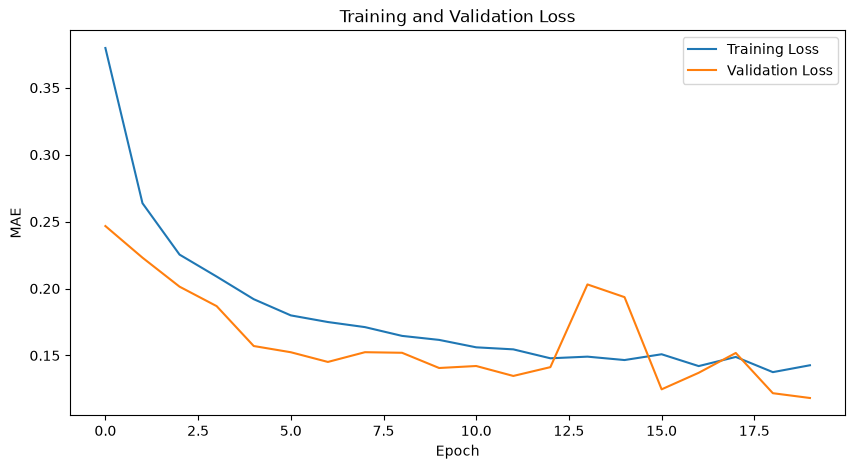

In [193]:
# Step 18 A
# Plot training history
plt.figure(figsize=(10, 5))

plt.plot(
    history_eva.history["loss"],
    label="Training Loss"
)

plt.plot(
    history_eva.history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("MAE")
plt.title("Training and Validation Loss")

plt.legend()

plt.show()

In [194]:
# Step 19 A
# Evaluate on the test dataset
test_results_eva = model_eva.evaluate(
    test_eva_ds,
    return_dict=True
)

print(test_results_eva)

 1/25 [>.............................] - ETA: 0s - loss: 0.1213 - MAE: 0.1213 - RMSE: 0.1586

25/25 [==============================] - 0s 3ms/step - loss: 0.1203 - MAE: 0.1203 - RMSE: 0.1629
{'loss': 0.12033742666244507, 'MAE': 0.12033742666244507, 'RMSE': 0.16293630003929138}


In [195]:
# Step 20 A
# Make predictions
y_eva_pred_scaled = model_eva.predict(
    X_eva_test,
    batch_size=BATCH_SIZE
)

print("Predictions shape:", y_eva_pred_scaled.shape)
print("Actual shape:", y_test.shape)

25/25 [==============================] - 1s 2ms/step
Predictions shape: (785, 5)
Actual shape: (785, 5)


In [196]:
# Step 21 A
# Convert predictions back to original speed
y_eva_pred = scaler.inverse_transform(y_eva_pred_scaled)

y_actual = scaler.inverse_transform(y_test)

In [197]:
# Step 22 A
# Calculate MAE and RMSE
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error

mae_eva = mean_absolute_error(
    y_actual.flatten(),
    y_eva_pred.flatten()
)

rmse_eva = np.sqrt(
    mean_squared_error(
        y_actual.flatten(),
        y_eva_pred.flatten()
    )
)

print(f"MAE:  {mae_eva:.3f}")
print(f"RMSE: {rmse_eva:.3f}")

MAE:  0.846
RMSE: 1.148


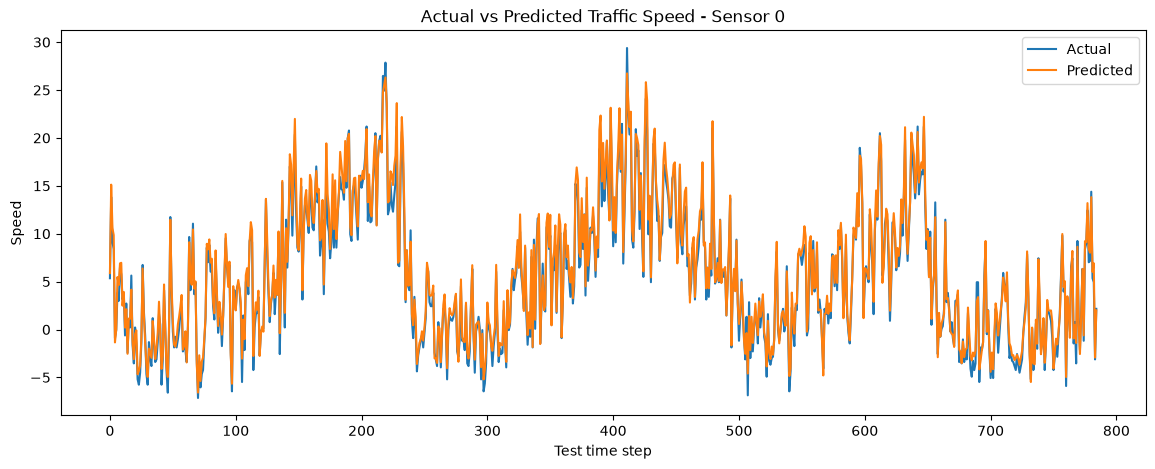

In [198]:
# Step 23 A
# Compare actual and predicted 
SENSOR_ID = 0

plt.figure(figsize=(14, 5))

plt.plot(
    y_actual[:, SENSOR_ID],
    label="Actual"
)

plt.plot(
    y_eva_pred[:, SENSOR_ID],
    label="Predicted"
)

plt.xlabel("Test time step")
plt.ylabel("Speed")

plt.title(
    f"Actual vs Predicted Traffic Speed - Sensor {SENSOR_ID}"
)

plt.legend()

plt.show()

While the above are the overall test results for all the 7 stations, the MAE is 0.6 much lower than the model developed in Part 2 

In the next I will remove rainfall attributes: 

In [199]:
# Step 1_attribute
n_dates_rain = df_all_5["Date_key"].nunique()

X_rain= df_all_5[feature_cols_rain_remove_7].to_numpy(dtype=np.float32)


X_rain = X_rain.reshape(n_dates_rain, 5, 7)


print("X:", X_rain.shape)


X: (5301, 5, 7)


In [200]:
#Step 2 attribute
# Normalize the traffic data
n = len(X_rain)

train_end = int(n * 0.70)
val_end = int(n * 0.85)

X_rain_train_data = X_rain[:train_end]
X_rain_val_data = X_rain[train_end:val_end]
X_rain_test_data = X_rain[val_end:]



print("X_Train:", X_rain_train_data.shape)
print("X_Validation:", X_rain_val_data.shape)
print("X_Test:", X_rain_test_data.shape)



X_Train: (3710, 5, 7)
X_Validation: (795, 5, 7)
X_Test: (796, 5, 7)


Then I scale the data 

In [201]:
# Step 3 attribute
from sklearn.preprocessing import StandardScaler

# Create scaler
scaler = StandardScaler()

# Fit only on training data
X_rain_train_data_scaled = scaler.fit_transform(X_rain_train_data.reshape(-1, 5)).reshape(X_rain_train_data.shape)
X_rain_val_data_scaled = scaler.transform(X_rain_val_data.reshape(-1, 5)).reshape(X_rain_val_data.shape)
X_rain_test_data_scaled = scaler.transform(X_rain_test_data.reshape(-1, 5)).reshape(X_rain_test_data.shape)




Then  create the temporal sequences. 

In [202]:
#Step 4 A
# Create temporal sequences
LOOK_BACK = 12

def create_X_sequences(data, look_back=12):
    X = []
    

    for i in range(len(data) - look_back +1):
        X.append(data[i:i + look_back])
        

    return np.array(X)




def create_Y_sequences(data, look_back=12):
    
    y = []

    for i in range(len(data) - look_back +1):
        
        y.append(data[i + look_back-1])

    return np.array(y)

In [203]:
# Step 5 A

# Create train/validation/test sequences
X_rain_train = create_X_sequences(
    X_rain_train_data_scaled,
    LOOK_BACK
)


X_rain_val = create_X_sequences(
    X_rain_val_data_scaled,
    LOOK_BACK
)



X_rain_test = create_X_sequences(
    X_rain_test_data_scaled,
    LOOK_BACK
)



In [210]:
# Step 6
print("X_train:", X_rain_train.shape)
print("X_val:", X_rain_val.shape)
print("X_test:", X_rain_test.shape)

X_train: (3699, 12, 5, 7)
X_val: (784, 12, 5, 7)
X_test: (785, 12, 5, 7)


In [ ]:
%pip install numpy==1.26.4

  Using cached numpy-1.26.4-cp311-cp311-win_amd64.whl.metadata (61 kB)
Using cached numpy-1.26.4-cp311-cp311-win_amd64.whl (15.8 MB)
  Attempting uninstall: numpy
    Found existing installation: numpy 2.4.6
    Uninstalling numpy-2.4.6:
      Successfully uninstalled numpy-2.4.6
Note: you may need to restart the kernel to use updated packages.


  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  You can safely remove it manually.
  You can safely remove it manually.
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
geopandas 1.2.0 requires numpy>=2, but you have numpy 1.26.4 which is incompatible.
ml-dtypes 0.6.0 requires numpy>=2.0.0, but you have numpy 1.26.4 which is incompatible.
opencv-python 5.0.0.93 requires numpy>=2; python_version >= "3.9", but you have numpy 1.26.4 which is incompatible.
salib 1.6.0 requires numpy>=2.0, but you have numpy 1.26.4 which is incompatible.

[notice] A new release of pip is available: 24.0 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


Create the batch size

In [205]:
#Step 8 A
# Create TensorFlow datasets
BATCH_SIZE = 32

train_rain_ds = tf.data.Dataset.from_tensor_slices(
    (X_rain_train, y_train)
).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

val_rain_ds = tf.data.Dataset.from_tensor_slices(
    (X_rain_val, y_val)
).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

test_rain_ds = tf.data.Dataset.from_tensor_slices(
    (X_rain_test, y_test)
).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

Here we have the design of the model. The model will have spatial first then temporal. First I have GCN to learn the relationship between the nodes, And then in each station has its own sequence and then temporal RNN to predict the weather then we have the prediction for each station and then altogether 

In [214]:
# Step 9 A
# ============================================================
# GCN + RNN
# One prediction for each node
# ============================================================

from tensorflow.keras.layers import (
    Input,
    SimpleRNN,
    Dense,
    TimeDistributed,
    Permute,
    Reshape
)
from tensorflow.keras.models import Model
from spektral.layers import GCNConv
import tensorflow as tf


# ------------------------------------------------------------
# Parameters
# ------------------------------------------------------------

TIME_STEPS = X_rain_train.shape[1]
NUM_NODES = X_rain_train.shape[2]
NUM_FEATURES_rain = X_rain_train.shape[3]

GCN_UNITS = 32
RNN_UNITS = 64


# ------------------------------------------------------------
# Input
# ------------------------------------------------------------

X_input_rain = Input(
    shape=(TIME_STEPS, NUM_NODES, NUM_FEATURES_rain),
    name="X_input_rain"
)


# ------------------------------------------------------------
# Adjacency matrix
# ------------------------------------------------------------

A_tensor = tf.constant(
    A,
    dtype=tf.float32
)


# ------------------------------------------------------------
# GCN
# ------------------------------------------------------------

gcn = GCNConv(
    GCN_UNITS,
    activation="relu",
    name="GCN"
)


# ------------------------------------------------------------
# GCN for every time step
# ------------------------------------------------------------

time_outputs = []

for t in range(TIME_STEPS):

    X_t = X_input_rain[:, t, :, :]

    X_gcn = gcn([
        X_t,
        A_tensor
    ])

    time_outputs.append(X_gcn)


# ------------------------------------------------------------
# Stack time dimension
# ------------------------------------------------------------

# (batch, time, nodes, GCN_UNITS)

x = tf.stack(
    time_outputs,
    axis=1
)


# ------------------------------------------------------------
# Move nodes before time
# ------------------------------------------------------------

# (batch, time, nodes, features)
#
#        ↓
#
# (batch, nodes, time, features)

x = Permute(
    (2, 1, 3),
    name="Node_Time_Permute"
)(x)


# ------------------------------------------------------------
# GRU for every node
# ------------------------------------------------------------

# TimeDistributed applies one GRU to each node sequence.
#
# Input:
# (batch, nodes, time, GCN_UNITS)
#
# Output:
# (batch, nodes, GRU_UNITS)

x = TimeDistributed(
    SimpleRNN(
        RNN_UNITS,
        return_sequences=False
    ),
    name="RNN_per_Node"
)(x)


# ------------------------------------------------------------
# Prediction for every node
# ------------------------------------------------------------

# Input:
# (batch, nodes, GRU_UNITS)
#
# Output:
# (batch, nodes, 1)

x = TimeDistributed(
    Dense(
        1
    ),
    name="Dense_per_Node"
)(x)


# ------------------------------------------------------------
# Remove final dimension
# ------------------------------------------------------------

# (batch, nodes, 1)
#
# ↓
#
# (batch, nodes)

outputs_rain = Reshape(
    (NUM_NODES,),
    name="Predictions"
)(x)


# ------------------------------------------------------------
# Model
# ------------------------------------------------------------

model_rain = Model(
    inputs=X_input_rain,
    outputs=outputs_rain,
    name="GCN_RNN"
)


# ------------------------------------------------------------
# Compile
# ------------------------------------------------------------

model_rain.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"]
)


# ------------------------------------------------------------
# Summary
# ------------------------------------------------------------

model_rain.summary()


# ------------------------------------------------------------
# Verify output
# ------------------------------------------------------------

print("Model output shape:", model_rain.output_shape)

Model: "GCN_RNN"
__________________________________________________________________________________________________
 Layer (type)                Output Shape                 Param #   Connected to                  
 X_input_rain (InputLayer)   [(None, 12, 5, 7)]           0         []                            
                                                                                                  
 tf.__operators__.getitem_3  (None, 5, 7)                 0         ['X_input_rain[0][0]']        
 00 (SlicingOpLambda)                                                                             
                                                                                                  
 tf.__operators__.getitem_3  (None, 5, 7)                 0         ['X_input_rain[0][0]']        
 01 (SlicingOpLambda)                                                                             
                                                                                            

Now we start to train the model 

In [215]:
# Step 10 A
print(A.shape)

early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

history_rain = model_rain.fit(
    X_rain_train,
    y_train,
    validation_data=(X_rain_val, y_val),
    epochs=50,
    batch_size=32,
    callbacks=[early_stopping]
)

(5, 5)
Epoch 1/50
116/116 [==============================] - 3s 8ms/step - loss: 0.3615 - mae: 0.4238 - val_loss: 0.3403 - val_mae: 0.3764
Epoch 2/50
116/116 [==============================] - 0s 4ms/step - loss: 0.3043 - mae: 0.3652 - val_loss: 0.3236 - val_mae: 0.3549
Epoch 3/50
116/116 [==============================] - 0s 4ms/step - loss: 0.2936 - mae: 0.3503 - val_loss: 0.3326 - val_mae: 0.3493
Epoch 4/50
116/116 [==============================] - 0s 4ms/step - loss: 0.2868 - mae: 0.3401 - val_loss: 0.3262 - val_mae: 0.3384
Epoch 5/50
116/116 [==============================] - 0s 4ms/step - loss: 0.2846 - mae: 0.3365 - val_loss: 0.3150 - val_mae: 0.3342
Epoch 6/50
116/116 [==============================] - 0s 3ms/step - loss: 0.2827 - mae: 0.3328 - val_loss: 0.3303 - val_mae: 0.3426
Epoch 7/50
116/116 [==============================] - 0s 3ms/step - loss: 0.2831 - mae: 0.3332 - val_loss: 0.3120 - val_mae: 0.3435
Epoch 8/50
116/116 [==============================] - 0s 4ms/step - l

In [216]:
# Step 11 A
class TemporalGCN(tf.keras.layers.Layer):
    def __init__(self, units, adjacency, **kwargs):
        super().__init__(**kwargs)

        self.adjacency = tf.constant(adjacency, dtype=tf.float32)

        self.gcn = GCNConv(
            units,
            activation="relu"
        )

    def call(self, inputs):
        time_outputs = []

        for t in range(inputs.shape[1]):
            x_t = inputs[:, t, :, :]
            x_gcn = self.gcn([x_t, self.adjacency])
            time_outputs.append(x_gcn)

        return tf.stack(time_outputs, axis=1)

In [217]:
# Step 12 A
# Create the GCN + RNN model
NUM_NODES = A.shape[0]
NUM_FEATURES_rain = 7

GCN_UNITS = 32
RNN_UNITS = 64

inputs = Input(
    shape=(LOOK_BACK, NUM_NODES, NUM_FEATURES_rain),
    name="weather_history"
)

# Spatial learning
x = TemporalGCN(
    GCN_UNITS,
    A_with_self_loops,
    name="temporal_gcn"
)(inputs)

print("After GCN:", x.shape)

After GCN: (None, 12, 5, 32)


In [218]:
# Step 13 A
x = tf.keras.layers.Permute(
    (2, 1, 3)
)(x)

print("After Permute:", x.shape)



x = tf.keras.layers.TimeDistributed(
    SimpleRNN(RNN_UNITS)
)(x)

print("After RNN:", x.shape)

After Permute: (None, 5, 12, 32)
After RNN: (None, 5, 64)


In [219]:
# Step 14 A

# Predict one value for every sensor:

outputs = tf.keras.layers.TimeDistributed(
    Dense(1)
)(x)

outputs = tf.keras.layers.Flatten()(outputs)

print("Output:", outputs.shape)

Output: (None, 5)


In [220]:
# Step 15 A
# Create the complete model
model_rain = Model(
    inputs=inputs,
    outputs=outputs
)

model_rain.summary()

Model: "model_9"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 weather_history (InputLaye  [(None, 12, 5, 7)]        0         
 r)                                                              
                                                                 
 temporal_gcn (TemporalGCN)  (None, 12, 5, 32)         256       
                                                                 
 permute_8 (Permute)         (None, 5, 12, 32)         0         
                                                                 
 time_distributed_13 (TimeD  (None, 5, 64)             6208      
 istributed)                                                     
                                                                 
 time_distributed_14 (TimeD  (None, 5, 1)              65        
 istributed)                                                     
                                                           

In [221]:
# Step 16 A

# Compile the model
model_rain.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="mae",
    metrics=[
        tf.keras.metrics.MeanAbsoluteError(name="MAE"),
        tf.keras.metrics.RootMeanSquaredError(name="RMSE")
    ]
)

In [222]:
# Step 17 A
# Train the model
EPOCHS = 20

early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

history_rain = model_rain.fit(
    train_rain_ds,
    validation_data=val_rain_ds,
    epochs=EPOCHS,
    callbacks=[early_stopping]
)

Epoch 1/20


116/116 [==============================] - 3s 8ms/step - loss: 0.3774 - MAE: 0.3774 - RMSE: 0.5280 - val_loss: 0.2099 - val_MAE: 0.2099 - val_RMSE: 0.2853
Epoch 2/20
116/116 [==============================] - 0s 4ms/step - loss: 0.2506 - MAE: 0.2506 - RMSE: 0.3219 - val_loss: 0.1845 - val_MAE: 0.1845 - val_RMSE: 0.2438
Epoch 3/20
116/116 [==============================] - 0s 4ms/step - loss: 0.2203 - MAE: 0.2203 - RMSE: 0.2844 - val_loss: 0.1658 - val_MAE: 0.1658 - val_RMSE: 0.2200
Epoch 4/20
116/116 [==============================] - 0s 4ms/step - loss: 0.2016 - MAE: 0.2016 - RMSE: 0.2639 - val_loss: 0.1610 - val_MAE: 0.1610 - val_RMSE: 0.2115
Epoch 5/20
116/116 [==============================] - 0s 4ms/step - loss: 0.1884 - MAE: 0.1884 - RMSE: 0.2478 - val_loss: 0.1580 - val_MAE: 0.1580 - val_RMSE: 0.2096
Epoch 6/20
116/116 [==============================] - 0s 3ms/step - loss: 0.1830 - MAE: 0.1830 - RMSE: 0.2416 - val_loss: 0.1536 - val_MAE: 0.1536 - val_RMSE: 0.2048
Epoch 7/20
116/

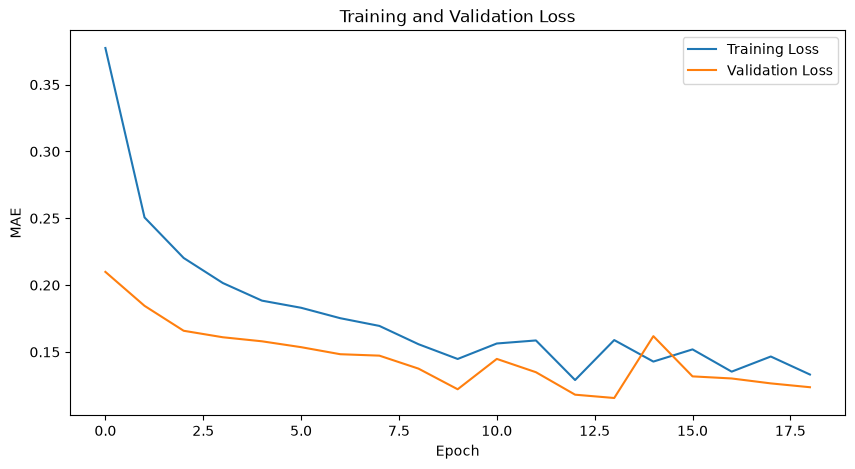

In [223]:
# Step 18 A
# Plot training history
plt.figure(figsize=(10, 5))

plt.plot(
    history_rain.history["loss"],
    label="Training Loss"
)

plt.plot(
    history_rain.history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("MAE")
plt.title("Training and Validation Loss")

plt.legend()

plt.show()

In [224]:
# Step 19 A
# Evaluate on the test dataset
test_results_rain = model_rain.evaluate(
    test_rain_ds,
    return_dict=True
)

print(test_results_rain)

 1/25 [>.............................] - ETA: 0s - loss: 0.1120 - MAE: 0.1120 - RMSE: 0.1508

25/25 [==============================] - 0s 3ms/step - loss: 0.1176 - MAE: 0.1176 - RMSE: 0.1651
{'loss': 0.11762125790119171, 'MAE': 0.11762125790119171, 'RMSE': 0.1650681048631668}


In [225]:
# Step 20 A
# Make predictions
y_rain_pred_scaled = model_rain.predict(
    X_rain_test,
    batch_size=BATCH_SIZE
)

print("Predictions shape:", y_rain_pred_scaled.shape)
print("Actual shape:", y_test.shape)

25/25 [==============================] - 1s 2ms/step
Predictions shape: (785, 5)
Actual shape: (785, 5)


In [226]:
# Step 21 A
# Convert predictions back to original speed
y_rain_pred = scaler.inverse_transform(y_rain_pred_scaled)

y_actual = scaler.inverse_transform(y_test)

In [227]:
# Step 22 A
# Calculate MAE and RMSE
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error

mae_rain = mean_absolute_error(
    y_actual.flatten(),
    y_rain_pred.flatten()
)

rmse_rain = np.sqrt(
    mean_squared_error(
        y_actual.flatten(),
        y_rain_pred.flatten()
    )
)

print(f"MAE:  {mae_rain:.3f}")
print(f"RMSE: {rmse_rain:.3f}")

MAE:  0.779
RMSE: 1.095


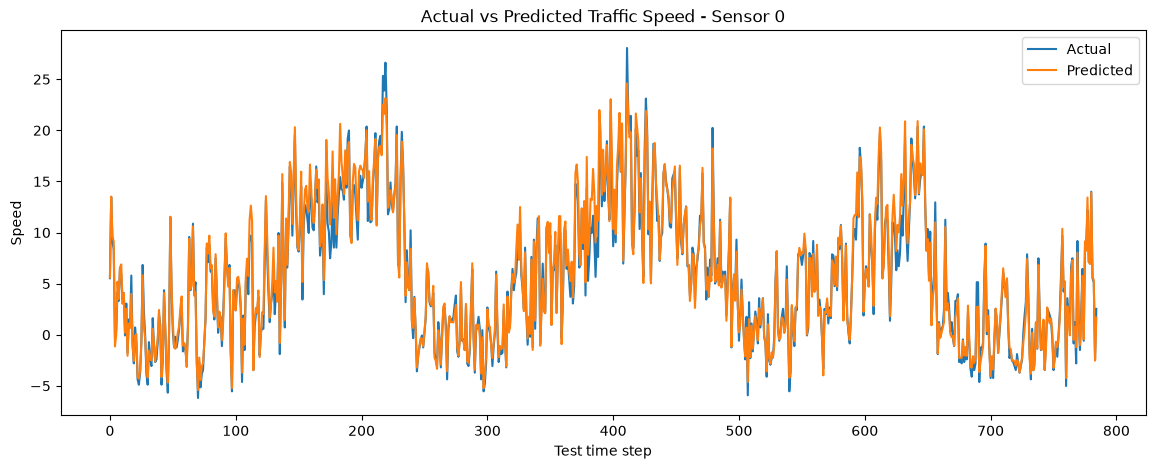

In [228]:
# Step 23 A
# Compare actual and predicted 
SENSOR_ID = 0

plt.figure(figsize=(14, 5))

plt.plot(
    y_actual[:, SENSOR_ID],
    label="Actual"
)

plt.plot(
    y_rain_pred[:, SENSOR_ID],
    label="Predicted"
)

plt.xlabel("Test time step")
plt.ylabel("Speed")

plt.title(
    f"Actual vs Predicted Traffic Speed - Sensor {SENSOR_ID}"
)

plt.legend()

plt.show()

In the next step I will remove the wind attribute 

In [229]:
# Step 1_attribute
n_dates_wind = df_all_5["Date_key"].nunique()

X_wind = df_all_5[feature_cols_wind_remove_7].to_numpy(dtype=np.float32)


X_wind = X_wind.reshape(n_dates_wind, 5, 7)


print("X:", X_wind.shape)


X: (5301, 5, 7)


In [230]:
#Step 2 attribute
# Normalize the traffic data
n = len(X_wind)

train_end = int(n * 0.70)
val_end = int(n * 0.85)

X_wind_train_data = X_wind[:train_end]
X_wind_val_data = X_wind[train_end:val_end]
X_wind_test_data = X_wind[val_end:]



print("X_Train:", X_wind_train_data.shape)
print("X_Validation:", X_wind_val_data.shape)
print("X_Test:", X_wind_test_data.shape)



X_Train: (3710, 5, 7)
X_Validation: (795, 5, 7)
X_Test: (796, 5, 7)


Then I scale the data 

In [231]:
# Step 3 attribute
from sklearn.preprocessing import StandardScaler

# Create scaler
scaler = StandardScaler()

# Fit only on training data
X_wind_train_data_scaled = scaler.fit_transform(X_wind_train_data.reshape(-1, 5)).reshape(X_wind_train_data.shape)
X_wind_val_data_scaled = scaler.transform(X_wind_val_data.reshape(-1, 5)).reshape(X_wind_val_data.shape)
X_wind_test_data_scaled = scaler.transform(X_wind_test_data.reshape(-1, 5)).reshape(X_wind_test_data.shape)




Then  create the temporal sequences. 

In [232]:
#Step 4 A
# Create temporal sequences
LOOK_BACK = 12

def create_X_sequences(data, look_back=12):
    X = []
    

    for i in range(len(data) - look_back +1):
        X.append(data[i:i + look_back])
        

    return np.array(X)




def create_Y_sequences(data, look_back=12):
    
    y = []

    for i in range(len(data) - look_back +1):
        
        y.append(data[i + look_back-1])

    return np.array(y)

In [233]:
# Step 5 A

# Create train/validation/test sequences
X_wind_train = create_X_sequences(
    X_wind_train_data_scaled,
    LOOK_BACK
)


X_wind_val = create_X_sequences(
    X_wind_val_data_scaled,
    LOOK_BACK
)



X_wind_test = create_X_sequences(
    X_wind_test_data_scaled,
    LOOK_BACK
)



In [234]:
# Step 6
print("X_train:", X_wind_train.shape)
print("X_val:", X_wind_val.shape)
print("X_test:", X_wind_test.shape)

X_train: (3699, 12, 5, 7)
X_val: (784, 12, 5, 7)
X_test: (785, 12, 5, 7)


In [ ]:
%pip install numpy==1.26.4

  Using cached numpy-1.26.4-cp311-cp311-win_amd64.whl.metadata (61 kB)
Using cached numpy-1.26.4-cp311-cp311-win_amd64.whl (15.8 MB)
  Attempting uninstall: numpy
    Found existing installation: numpy 2.4.6
    Uninstalling numpy-2.4.6:
      Successfully uninstalled numpy-2.4.6
Note: you may need to restart the kernel to use updated packages.


  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  You can safely remove it manually.
  You can safely remove it manually.
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
geopandas 1.2.0 requires numpy>=2, but you have numpy 1.26.4 which is incompatible.
ml-dtypes 0.6.0 requires numpy>=2.0.0, but you have numpy 1.26.4 which is incompatible.
opencv-python 5.0.0.93 requires numpy>=2; python_version >= "3.9", but you have numpy 1.26.4 which is incompatible.
salib 1.6.0 requires numpy>=2.0, but you have numpy 1.26.4 which is incompatible.

[notice] A new release of pip is available: 24.0 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


Create the batch size

In [235]:
#Step 8 A
# Create TensorFlow datasets
BATCH_SIZE = 32

train_wind_ds = tf.data.Dataset.from_tensor_slices(
    (X_wind_train, y_train)
).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

val_wind_ds = tf.data.Dataset.from_tensor_slices(
    (X_wind_val, y_val)
).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

test_wind_ds = tf.data.Dataset.from_tensor_slices(
    (X_wind_test, y_test)
).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

Here we have the design of the model. The model will have spatial first then temporal. First I have GCN to learn the relationship between the nodes, And then in each station has its own sequence and then temporal RNN to predict the weather then we have the prediction for each station and then altogether 

In [237]:
# Step 9 A
# ============================================================
# GCN + RNN
# One prediction for each node
# ============================================================

from tensorflow.keras.layers import (
    Input,
    SimpleRNN,
    Dense,
    TimeDistributed,
    Permute,
    Reshape
)
from tensorflow.keras.models import Model
from spektral.layers import GCNConv
import tensorflow as tf


# ------------------------------------------------------------
# Parameters
# ------------------------------------------------------------

TIME_STEPS = X_wind_train.shape[1]
NUM_NODES = X_wind_train.shape[2]
NUM_FEATURES_wind = X_wind_train.shape[3]

GCN_UNITS = 32
RNN_UNITS = 64


# ------------------------------------------------------------
# Input
# ------------------------------------------------------------

X_input_wind = Input(
    shape=(TIME_STEPS, NUM_NODES, NUM_FEATURES_wind),
    name="X_input_wind"
)


# ------------------------------------------------------------
# Adjacency matrix
# ------------------------------------------------------------

A_tensor = tf.constant(
    A,
    dtype=tf.float32
)


# ------------------------------------------------------------
# GCN
# ------------------------------------------------------------

gcn = GCNConv(
    GCN_UNITS,
    activation="relu",
    name="GCN"
)


# ------------------------------------------------------------
# GCN for every time step
# ------------------------------------------------------------

time_outputs = []

for t in range(TIME_STEPS):

    X_t = X_input_wind[:, t, :, :]

    X_gcn = gcn([
        X_t,
        A_tensor
    ])

    time_outputs.append(X_gcn)


# ------------------------------------------------------------
# Stack time dimension
# ------------------------------------------------------------

# (batch, time, nodes, GCN_UNITS)

x = tf.stack(
    time_outputs,
    axis=1
)


# ------------------------------------------------------------
# Move nodes before time
# ------------------------------------------------------------

# (batch, time, nodes, features)
#
#        ↓
#
# (batch, nodes, time, features)

x = Permute(
    (2, 1, 3),
    name="Node_Time_Permute"
)(x)


# ------------------------------------------------------------
# GRU for every node
# ------------------------------------------------------------

# TimeDistributed applies one GRU to each node sequence.
#
# Input:
# (batch, nodes, time, GCN_UNITS)
#
# Output:
# (batch, nodes, GRU_UNITS)

x = TimeDistributed(
    SimpleRNN(
        RNN_UNITS,
        return_sequences=False
    ),
    name="RNN_per_Node"
)(x)


# ------------------------------------------------------------
# Prediction for every node
# ------------------------------------------------------------

# Input:
# (batch, nodes, GRU_UNITS)
#
# Output:
# (batch, nodes, 1)

x = TimeDistributed(
    Dense(
        1
    ),
    name="Dense_per_Node"
)(x)


# ------------------------------------------------------------
# Remove final dimension
# ------------------------------------------------------------

# (batch, nodes, 1)
#
# ↓
#
# (batch, nodes)

outputs_wind = Reshape(
    (NUM_NODES,),
    name="Predictions"
)(x)


# ------------------------------------------------------------
# Model
# ------------------------------------------------------------

model_wind = Model(
    inputs=X_input_wind,
    outputs=outputs_wind,
    name="GCN_RNN"
)


# ------------------------------------------------------------
# Compile
# ------------------------------------------------------------

model_wind.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"]
)


# ------------------------------------------------------------
# Summary
# ------------------------------------------------------------

model_wind.summary()


# ------------------------------------------------------------
# Verify output
# ------------------------------------------------------------

print("Model output shape:", model_wind.output_shape)

Model: "GCN_RNN"
__________________________________________________________________________________________________
 Layer (type)                Output Shape                 Param #   Connected to                  
 X_input_wind (InputLayer)   [(None, 12, 5, 7)]           0         []                            
                                                                                                  
 tf.__operators__.getitem_3  (None, 5, 7)                 0         ['X_input_wind[0][0]']        
 24 (SlicingOpLambda)                                                                             
                                                                                                  
 tf.__operators__.getitem_3  (None, 5, 7)                 0         ['X_input_wind[0][0]']        
 25 (SlicingOpLambda)                                                                             
                                                                                            

Now we start to train the model 

In [238]:
# Step 10 A
print(A.shape)

early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

history_wind = model_wind.fit(
    X_wind_train,
    y_train,
    validation_data=(X_wind_val, y_val),
    epochs=50,
    batch_size=32,
    callbacks=[early_stopping]
)

(5, 5)
Epoch 1/50
116/116 [==============================] - 3s 9ms/step - loss: 0.4385 - mae: 0.4738 - val_loss: 0.3437 - val_mae: 0.3905
Epoch 2/50
116/116 [==============================] - 0s 4ms/step - loss: 0.3138 - mae: 0.3755 - val_loss: 0.3336 - val_mae: 0.3641
Epoch 3/50
116/116 [==============================] - 0s 4ms/step - loss: 0.2958 - mae: 0.3523 - val_loss: 0.3233 - val_mae: 0.3485
Epoch 4/50
116/116 [==============================] - 0s 4ms/step - loss: 0.2888 - mae: 0.3420 - val_loss: 0.3228 - val_mae: 0.3421
Epoch 5/50
116/116 [==============================] - 0s 4ms/step - loss: 0.2842 - mae: 0.3356 - val_loss: 0.3186 - val_mae: 0.3391
Epoch 6/50
116/116 [==============================] - 0s 4ms/step - loss: 0.2820 - mae: 0.3321 - val_loss: 0.3160 - val_mae: 0.3345
Epoch 7/50
116/116 [==============================] - 0s 4ms/step - loss: 0.2805 - mae: 0.3290 - val_loss: 0.3238 - val_mae: 0.3331
Epoch 8/50
116/116 [==============================] - 0s 4ms/step - l

In [239]:
# Step 11 A
class TemporalGCN(tf.keras.layers.Layer):
    def __init__(self, units, adjacency, **kwargs):
        super().__init__(**kwargs)

        self.adjacency = tf.constant(adjacency, dtype=tf.float32)

        self.gcn = GCNConv(
            units,
            activation="relu"
        )

    def call(self, inputs):
        time_outputs = []

        for t in range(inputs.shape[1]):
            x_t = inputs[:, t, :, :]
            x_gcn = self.gcn([x_t, self.adjacency])
            time_outputs.append(x_gcn)

        return tf.stack(time_outputs, axis=1)

In [240]:
# Step 12 A
# Create the GCN + RNN model
NUM_NODES = A.shape[0]
NUM_FEATURES_wind = 7

GCN_UNITS = 32
RNN_UNITS = 64

inputs = Input(
    shape=(LOOK_BACK, NUM_NODES, NUM_FEATURES_wind),
    name="weather_history"
)

# Spatial learning
x = TemporalGCN(
    GCN_UNITS,
    A_with_self_loops,
    name="temporal_gcn"
)(inputs)

print("After GCN:", x.shape)

After GCN: (None, 12, 5, 32)


In [241]:
# Step 13 A
x = tf.keras.layers.Permute(
    (2, 1, 3)
)(x)

print("After Permute:", x.shape)



x = tf.keras.layers.TimeDistributed(
    SimpleRNN(RNN_UNITS)
)(x)

print("After RNN:", x.shape)

After Permute: (None, 5, 12, 32)
After RNN: (None, 5, 64)


In [242]:
# Step 14 A

# Predict one value for every sensor:

outputs = tf.keras.layers.TimeDistributed(
    Dense(1)
)(x)

outputs = tf.keras.layers.Flatten()(outputs)

print("Output:", outputs.shape)

Output: (None, 5)


In [168]:
# Step 15 A
# Create the complete model
model_wind = Model(
    inputs=inputs,
    outputs=outputs
)

model_wind.summary()

Model: "model_5"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 weather_history (InputLaye  [(None, 12, 5, 7)]        0         
 r)                                                              
                                                                 
 temporal_gcn (TemporalGCN)  (None, 12, 5, 32)         256       
                                                                 
 permute_6 (Permute)         (None, 5, 12, 32)         0         
                                                                 
 time_distributed_9 (TimeDi  (None, 5, 64)             6208      
 stributed)                                                      
                                                                 
 time_distributed_10 (TimeD  (None, 5, 1)              65        
 istributed)                                                     
                                                           

In [243]:
# Step 16 A

# Compile the model
model_wind.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="mae",
    metrics=[
        tf.keras.metrics.MeanAbsoluteError(name="MAE"),
        tf.keras.metrics.RootMeanSquaredError(name="RMSE")
    ]
)

In [244]:
# Step 17 A
# Train the model
EPOCHS = 20

early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

history_wind = model_wind.fit(
    train_wind_ds,
    validation_data=val_wind_ds,
    epochs=EPOCHS,
    callbacks=[early_stopping]
)

Epoch 1/20


116/116 [==============================] - 3s 9ms/step - loss: 0.4224 - MAE: 0.4224 - RMSE: 0.6081 - val_loss: 0.3827 - val_MAE: 0.3827 - val_RMSE: 0.6004
Epoch 2/20
116/116 [==============================] - 0s 4ms/step - loss: 0.3638 - MAE: 0.3638 - RMSE: 0.5536 - val_loss: 0.3642 - val_MAE: 0.3642 - val_RMSE: 0.5857
Epoch 3/20
116/116 [==============================] - 0s 4ms/step - loss: 0.3638 - MAE: 0.3638 - RMSE: 0.5516 - val_loss: 0.3580 - val_MAE: 0.3580 - val_RMSE: 0.5790
Epoch 4/20
116/116 [==============================] - 0s 4ms/step - loss: 0.3438 - MAE: 0.3438 - RMSE: 0.5406 - val_loss: 0.3450 - val_MAE: 0.3450 - val_RMSE: 0.5712
Epoch 5/20
116/116 [==============================] - 0s 4ms/step - loss: 0.3471 - MAE: 0.3471 - RMSE: 0.5429 - val_loss: 0.3348 - val_MAE: 0.3348 - val_RMSE: 0.5663
Epoch 6/20
116/116 [==============================] - 0s 4ms/step - loss: 0.3555 - MAE: 0.3555 - RMSE: 0.5481 - val_loss: 0.3410 - val_MAE: 0.3410 - val_RMSE: 0.5697
Epoch 7/20
116/

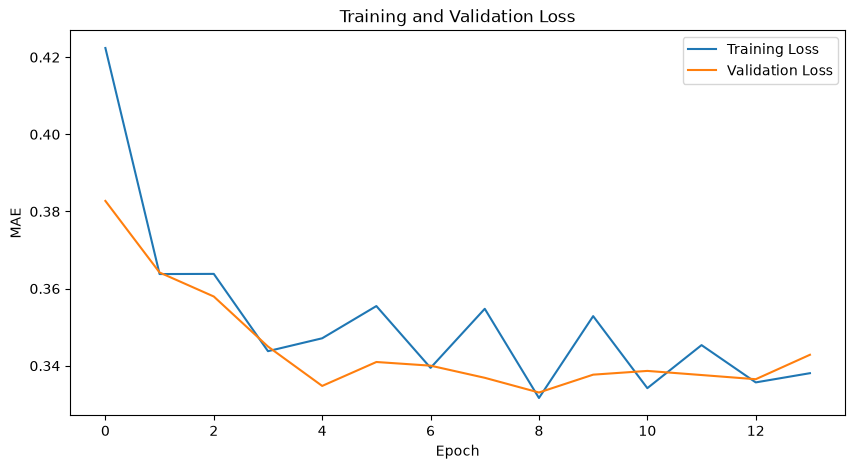

In [245]:
# Step 18 A
# Plot training history
plt.figure(figsize=(10, 5))

plt.plot(
    history_wind.history["loss"],
    label="Training Loss"
)

plt.plot(
    history_wind.history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("MAE")
plt.title("Training and Validation Loss")

plt.legend()

plt.show()

In [246]:
# Step 19 A
# Evaluate on the test dataset
test_results_wind = model_wind.evaluate(
    test_wind_ds,
    return_dict=True
)

print(test_results_wind)

 1/25 [>.............................] - ETA: 0s - loss: 0.3084 - MAE: 0.3084 - RMSE: 0.4765

25/25 [==============================] - 0s 4ms/step - loss: 0.3265 - MAE: 0.3265 - RMSE: 0.5424
{'loss': 0.32647350430488586, 'MAE': 0.32647350430488586, 'RMSE': 0.5424094796180725}


In [247]:
# Step 20 A
# Make predictions
y_wind_pred_scaled = model_rain.predict(
    X_wind_test,
    batch_size=BATCH_SIZE
)

print("Predictions shape:", y_wind_pred_scaled.shape)
print("Actual shape:", y_test.shape)

25/25 [==============================] - 0s 4ms/step
Predictions shape: (785, 5)
Actual shape: (785, 5)


In [248]:
# Step 21 A
# Convert predictions back to original speed
y_wind_pred = scaler.inverse_transform(y_wind_pred_scaled)

y_actual = scaler.inverse_transform(y_test)

In [249]:
# Step 22 A
# Calculate MAE and RMSE
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error

mae_wind = mean_absolute_error(
    y_actual.flatten(),
    y_wind_pred.flatten()
)

rmse_wind = np.sqrt(
    mean_squared_error(
        y_actual.flatten(),
        y_wind_pred.flatten()
    )
)

print(f"MAE:  {mae_wind:.3f}")
print(f"RMSE: {rmse_wind:.3f}")

MAE:  1.142
RMSE: 1.686


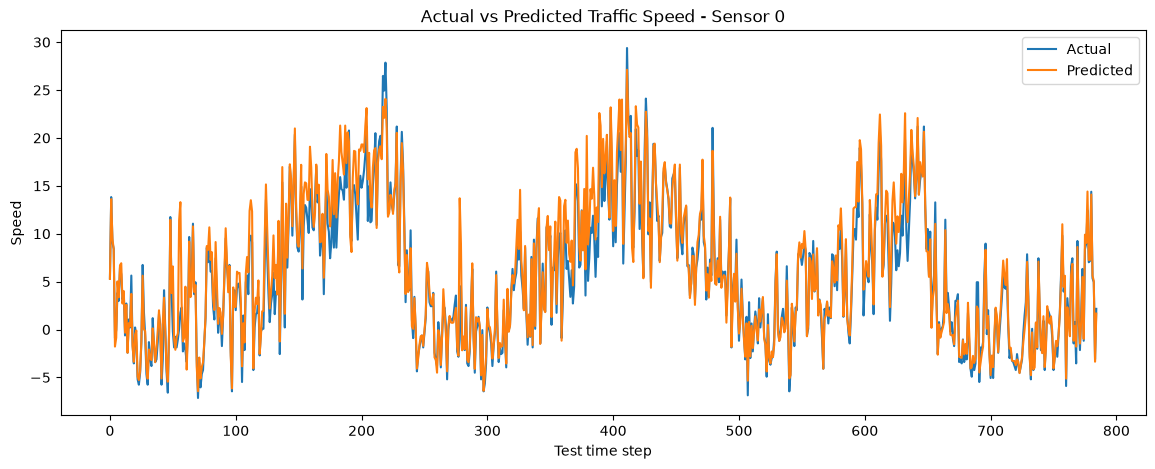

In [250]:
# Step 23 A
# Compare actual and predicted 
SENSOR_ID = 0

plt.figure(figsize=(14, 5))

plt.plot(
    y_actual[:, SENSOR_ID],
    label="Actual"
)

plt.plot(
    y_wind_pred[:, SENSOR_ID],
    label="Predicted"
)

plt.xlabel("Test time step")
plt.ylabel("Speed")

plt.title(
    f"Actual vs Predicted Traffic Speed - Sensor {SENSOR_ID}"
)

plt.legend()

plt.show()

In the next step I will replace each station from the matrix 

In this case I will remove the station of CA 

we can see the distance between the stations and from that, we can see that  Christchurch, Kyle St EWS (RK), Rangiora EWS (RE) and Christchurch Aero (CA) are closer to each other with the distance < 50 km>, I can say that their connection are 1. Mean while, ASHBURTON AERO AWS (AA) and Hanmer Forest EWS (HF) are far from each other and far from the three other nodes, so their connections to each other is 0 

In [265]:
# Step 1N
nodes_CA = list(range(4))

print(nodes)

[0, 1, 2, 3]


We will name  CK:0, AA:1, RE:2, HF:3. In the next I identify assign the edges weight to the nodes 

In [266]:
# Step 2N
edges_CA = [
    (0, 2),
    (2, 0),

    

]

In [267]:
# Step 3N
A_CA = np.zeros((4, 4))

for i, j in edges_not_CA:
    A_CA[i, j] = 1

print(A_CA)

[[0. 0. 1. 0.]
 [0. 0. 0. 0.]
 [1. 0. 0. 0.]
 [0. 0. 0. 0.]]


Next I need to remove station CA from the node feature table

In [268]:
# Step 4N
df_all_CA = df_all_5[df_all_5['Station']!="CA"]

print(df_all_CA[["Date_key", "Station", "Station Order"]].head(10))

      Date_key Station  Station Order
1   2006-02-24      CK              2
2   2006-02-24      AA              3
3   2006-02-24      RE              4
4   2006-02-24      HF              5
6   2006-03-04      CK              2
7   2006-03-04      AA              3
8   2006-03-04      RE              4
9   2006-03-04      HF              5
11  2006-03-05      CK              2
12  2006-03-05      AA              3


In [269]:
# Step 5N
# Check the adjacency matrix
print("A shape:", A_CA.shape)
print("A minimum:", A_CA.min())
print("A maximum:", A_CA.max())
print("Non-zero edges:", np.count_nonzero(A_CA))

A shape: (4, 4)
A minimum: 0.0
A maximum: 1.0
Non-zero edges: 2


In [270]:
# Step 6N
# Add self-loops:

A_CA = A_CA.astype(np.float32)

A_with_self_loops_CA = A_CA + np.eye(A_CA.shape[0], dtype=np.float32)

print("Original non-zero values:",
      np.count_nonzero(A_CA))

print("After adding self-loops:",
      np.count_nonzero(A_with_self_loops_CA))

Original non-zero values: 2
After adding self-loops: 6


In [274]:
# Step 7N
n_dates_CA = df_all_CA["Date_key"].nunique()

X_CA = df_all_CA[feature_cols].to_numpy(dtype=np.float32)
y_CA = df_all_CA[target_col].to_numpy(dtype=np.float32)

X_CA = X_CA.reshape(n_dates_CA, 4, 8)
y_CA = y_CA.reshape(n_dates_CA, 4)

print("X:", X_CA.shape)
print("y:", y_CA.shape)

X: (5301, 4, 8)
y: (5301, 4)


In [ ]:
# Step 8N
# Normalize the traffic data
n_CA = len(X_CA)

train_end_CA = int(n * 0.70)
val_end_CA = int(n * 0.85)

X_train_data_CA = X_CA[:train_end_CA]
X_val_data_CA = X_CA[train_end_CA:val_end_CA]
X_test_data_CA = X_CA[val_end_CA:]

y_train_data_CA = y_CA[:train_end_CA]
y_val_data_CA = y_CA[train_end_CA:val_end_CA]
y_test_data_CA = y[val_end_CA:]

print("X_Train:", X_train_data_CA.shape)
print("X_Validation:", X_val_data_CA.shape)
print("X_Test:", X_test_data_CA.shape)

print("y_Train:", y_train_data_CA.shape)
print("y_Validation:", y_val_data_CA.shape)
print("y_Test:", y_test_data_CA.shape)

X_Train: (3710, 4, 8)
X_Validation: (795, 4, 8)
X_Test: (796, 4, 8)
y_Train: (3710, 4)
y_Validation: (795, 4)
y_Test: (796, 4)


In [276]:
# Step 9N
from sklearn.preprocessing import StandardScaler

# Create scaler
scaler = StandardScaler()

# Fit only on training data
X_train_data_scaled_CA = scaler.fit_transform(X_train_data_CA.reshape(-1, 8)).reshape(X_train_data_CA.shape)
X_val_data_scaled_CA = scaler.transform(X_val_data_CA.reshape(-1, 8)).reshape(X_val_data_CA.shape)
X_test_data_scaled_CA = scaler.transform(X_test_data_CA.reshape(-1, 8)).reshape(X_test_data_CA.shape)


y_train_data_scaled_CA = scaler.fit_transform(y_train_data_CA.reshape(-1, 1)).reshape(y_train_data_CA.shape)
y_val_data_scaled_CA = scaler.transform(y_val_data_CA.reshape(-1, 1)).reshape(y_val_data_CA.shape)
y_test_data_scaled_CA = scaler.transform(y_test_data_CA.reshape(-1, 1)).reshape(y_test_data_CA.shape)

In [277]:
# Step 10N

# Create train/validation/test sequences
X_train_CA = create_X_sequences(
    X_train_data_scaled_CA,
    LOOK_BACK
)

y_train_CA = create_Y_sequences(
    y_train_data_scaled_CA,
    LOOK_BACK
)

X_val_CA = create_X_sequences(
    X_val_data_scaled_CA,
    LOOK_BACK
)

y_val_CA = create_Y_sequences(
    y_val_data_scaled_CA,
    LOOK_BACK
)

X_test_CA = create_X_sequences(
    X_test_data_scaled_CA,
    LOOK_BACK
)

y_test_CA = create_Y_sequences(
    y_test_data_scaled_CA,
    LOOK_BACK
)

In [278]:
# Step 11N
print("X_train:", X_train_CA.shape)
print("X_val:", X_val_CA.shape)
print("X_test:", X_test_CA.shape)

X_train: (3699, 12, 4, 8)
X_val: (784, 12, 4, 8)
X_test: (785, 12, 4, 8)


In [ ]:
# Step 12N
print("Y_train:", y_train_CA.shape)
print("Y_val:", y_val_CA.shape)
print("Y_test:", y_test_CA.shape)

Y_train: (3699, 4)
Y_val: (784, 4)
Y_test: (785, 4)


In [280]:
# Step 13N
# Create TensorFlow datasets
BATCH_SIZE = 32

train_ds_CA = tf.data.Dataset.from_tensor_slices(
    (X_train_CA, y_train_CA)
).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

val_ds_CA = tf.data.Dataset.from_tensor_slices(
    (X_val_CA, y_val_CA)
).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

test_ds_CA = tf.data.Dataset.from_tensor_slices(
    (X_test_CA, y_test_CA)
).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

In [282]:
# Step 14N
# ============================================================
# GCN + RNN
# One prediction for each node
# ============================================================

from tensorflow.keras.layers import (
    Input,
    SimpleRNN,
    Dense,
    TimeDistributed,
    Permute,
    Reshape
)
from tensorflow.keras.models import Model
from spektral.layers import GCNConv
import tensorflow as tf


# ------------------------------------------------------------
# Parameters
# ------------------------------------------------------------

TIME_STEPS = X_train_CA.shape[1]
NUM_NODES_CA = X_train_CA.shape[2]
NUM_FEATURES_CA = X_train_CA.shape[3]

GCN_UNITS = 32
RNN_UNITS = 64


# ------------------------------------------------------------
# Input
# ------------------------------------------------------------

X_input_CA= Input(
    shape=(TIME_STEPS, NUM_NODES_CA, NUM_FEATURES_CA),
    name="X_input_CA"
)


# ------------------------------------------------------------
# Adjacency matrix
# ------------------------------------------------------------

A_tensor_CA = tf.constant(
    A_CA,
    dtype=tf.float32
)


# ------------------------------------------------------------
# GCN
# ------------------------------------------------------------

gcn = GCNConv(
    GCN_UNITS,
    activation="relu",
    name="GCN"
)


# ------------------------------------------------------------
# GCN for every time step
# ------------------------------------------------------------

time_outputs = []

for t in range(TIME_STEPS):

    X_t = X_input_CA[:, t, :, :]

    X_gcn = gcn([
        X_t,
        A_tensor_CA
    ])

    time_outputs.append(X_gcn)


# ------------------------------------------------------------
# Stack time dimension
# ------------------------------------------------------------

# (batch, time, nodes, GCN_UNITS)

x = tf.stack(
    time_outputs,
    axis=1
)


# ------------------------------------------------------------
# Move nodes before time
# ------------------------------------------------------------

# (batch, time, nodes, features)
#
#        ↓
#
# (batch, nodes, time, features)

x = Permute(
    (2, 1, 3),
    name="Node_Time_Permute"
)(x)


# ------------------------------------------------------------
# GRU for every node
# ------------------------------------------------------------

# TimeDistributed applies one GRU to each node sequence.
#
# Input:
# (batch, nodes, time, GCN_UNITS)
#
# Output:
# (batch, nodes, GRU_UNITS)

x = TimeDistributed(
    SimpleRNN(
        RNN_UNITS,
        return_sequences=False
    ),
    name="RNN_per_Node"
)(x)


# ------------------------------------------------------------
# Prediction for every node
# ------------------------------------------------------------

# Input:
# (batch, nodes, GRU_UNITS)
#
# Output:
# (batch, nodes, 1)

x = TimeDistributed(
    Dense(
        1
    ),
    name="Dense_per_Node"
)(x)


# ------------------------------------------------------------
# Remove final dimension
# ------------------------------------------------------------

# (batch, nodes, 1)
#
# ↓
#
# (batch, nodes)

outputs_CA = Reshape(
    (NUM_NODES_CA,),
    name="Predictions"
)(x)


# ------------------------------------------------------------
# Model
# ------------------------------------------------------------

model_CA = Model(
    inputs=X_input_CA,
    outputs=outputs_CA,
    name="GCN_RNN"
)


# ------------------------------------------------------------
# Compile
# ------------------------------------------------------------

model_CA.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"]
)


# ------------------------------------------------------------
# Summary
# ------------------------------------------------------------

model_CA.summary()


# ------------------------------------------------------------
# Verify output
# ------------------------------------------------------------

print("Model output shape:", model_CA.output_shape)

Model: "GCN_RNN"
__________________________________________________________________________________________________
 Layer (type)                Output Shape                 Param #   Connected to                  
 X_input_CA (InputLayer)     [(None, 12, 4, 8)]           0         []                            
                                                                                                  
 tf.__operators__.getitem_3  (None, 4, 8)                 0         ['X_input_CA[0][0]']          
 48 (SlicingOpLambda)                                                                             
                                                                                                  
 tf.__operators__.getitem_3  (None, 4, 8)                 0         ['X_input_CA[0][0]']          
 49 (SlicingOpLambda)                                                                             
                                                                                            

In [283]:
print(A_CA.shape)

early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

history_CA = model_CA.fit(
    X_train_CA,
    y_train_CA,
    validation_data=(X_val_CA, y_val_CA),
    epochs=50,
    batch_size=32,
    callbacks=[early_stopping]
)

(4, 4)
Epoch 1/50
116/116 [==============================] - 3s 8ms/step - loss: 0.5980 - mae: 0.5670 - val_loss: 0.6317 - val_mae: 0.5640
Epoch 2/50
116/116 [==============================] - 0s 4ms/step - loss: 0.5698 - mae: 0.5385 - val_loss: 0.6333 - val_mae: 0.5583
Epoch 3/50
116/116 [==============================] - 0s 4ms/step - loss: 0.5667 - mae: 0.5334 - val_loss: 0.6357 - val_mae: 0.5551
Epoch 4/50
116/116 [==============================] - 0s 3ms/step - loss: 0.5646 - mae: 0.5303 - val_loss: 0.6173 - val_mae: 0.5481
Epoch 5/50
116/116 [==============================] - 0s 3ms/step - loss: 0.5644 - mae: 0.5293 - val_loss: 0.6242 - val_mae: 0.5494
Epoch 6/50
116/116 [==============================] - 0s 4ms/step - loss: 0.5624 - mae: 0.5265 - val_loss: 0.6238 - val_mae: 0.5481
Epoch 7/50
116/116 [==============================] - 0s 3ms/step - loss: 0.5620 - mae: 0.5263 - val_loss: 0.6207 - val_mae: 0.5446
Epoch 8/50
116/116 [==============================] - 0s 3ms/step - l

In [284]:
# Create the GCN + RNN model
NUM_NODES_CA = A_CA.shape[0]
NUM_FEATURES = 8

GCN_UNITS = 32
RNN_UNITS = 64

inputs = Input(
    shape=(LOOK_BACK, NUM_NODES_CA, NUM_FEATURES),
    name="weather_history"
)

# Spatial learning
x = TemporalGCN(
    GCN_UNITS,
    A_with_self_loops_CA,
    name="temporal_gcn"
)(inputs)

print("After GCN:", x.shape)

After GCN: (None, 12, 4, 32)


In [285]:
x = tf.keras.layers.Permute(
    (2, 1, 3)
)(x)

print("After Permute:", x.shape)



x = tf.keras.layers.TimeDistributed(
    SimpleRNN(RNN_UNITS)
)(x)

print("After RNN:", x.shape)

After Permute: (None, 4, 12, 32)
After RNN: (None, 4, 64)


In [286]:
# Predict one value for every sensor:

outputs = tf.keras.layers.TimeDistributed(
    Dense(1)
)(x)

outputs = tf.keras.layers.Flatten()(outputs)

print("Output:", outputs.shape)

Output: (None, 4)


In [287]:
# Create the complete model
model_CA = Model(
    inputs=inputs,
    outputs=outputs
)

model_CA.summary()

Model: "model_10"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 weather_history (InputLaye  [(None, 12, 4, 8)]        0         
 r)                                                              
                                                                 
 temporal_gcn (TemporalGCN)  (None, 12, 4, 32)         288       
                                                                 
 permute_10 (Permute)        (None, 4, 12, 32)         0         
                                                                 
 time_distributed_17 (TimeD  (None, 4, 64)             6208      
 istributed)                                                     
                                                                 
 time_distributed_18 (TimeD  (None, 4, 1)              65        
 istributed)                                                     
                                                          

In [288]:
# Compile the model
model_CA.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="mae",
    metrics=[
        tf.keras.metrics.MeanAbsoluteError(name="MAE"),
        tf.keras.metrics.RootMeanSquaredError(name="RMSE")
    ]
)

In [289]:
# Train the model
EPOCHS = 20

early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

history = model_CA.fit(
    train_ds_CA,
    validation_data=val_ds_CA,
    epochs=EPOCHS,
    callbacks=[early_stopping]
)

Epoch 1/20
116/116 [==============================] - 3s 8ms/step - loss: 0.3461 - MAE: 0.3461 - RMSE: 0.4843 - val_loss: 0.2772 - val_MAE: 0.2772 - val_RMSE: 0.3580
Epoch 2/20
116/116 [==============================] - 0s 3ms/step - loss: 0.2789 - MAE: 0.2789 - RMSE: 0.3543 - val_loss: 0.2079 - val_MAE: 0.2079 - val_RMSE: 0.2754
Epoch 3/20
116/116 [==============================] - 0s 3ms/step - loss: 0.2165 - MAE: 0.2165 - RMSE: 0.2826 - val_loss: 0.2015 - val_MAE: 0.2015 - val_RMSE: 0.2693
Epoch 4/20
116/116 [==============================] - 0s 4ms/step - loss: 0.2291 - MAE: 0.2291 - RMSE: 0.2992 - val_loss: 0.1840 - val_MAE: 0.1840 - val_RMSE: 0.2509
Epoch 5/20
116/116 [==============================] - 0s 3ms/step - loss: 0.2006 - MAE: 0.2006 - RMSE: 0.2667 - val_loss: 0.1731 - val_MAE: 0.1731 - val_RMSE: 0.2383
Epoch 6/20
116/116 [==============================] - 0s 3ms/step - loss: 0.1972 - MAE: 0.1972 - RMSE: 0.2640 - val_loss: 0.1687 - val_MAE: 0.1687 - val_RMSE: 0.2346
Epoc

In [290]:
# Evaluate on the test dataset
test_results_CA = model_CA.evaluate(
    test_ds_CA,
    return_dict=True
)

print(test_results_CA)

25/25 [==============================] - 0s 3ms/step - loss: 0.0998 - MAE: 0.0998 - RMSE: 0.1385
{'loss': 0.09976121783256531, 'MAE': 0.09976121783256531, 'RMSE': 0.13848885893821716}


In [291]:
# Make predictions
y_pred_scaled_CA = model_CA.predict(
    X_test_CA,
    batch_size=BATCH_SIZE
)

print("Predictions shape:", y_pred_scaled_CA.shape)
print("Actual shape:", y_test_CA.shape)

25/25 [==============================] - 1s 2ms/step
Predictions shape: (785, 4)
Actual shape: (785, 4)


In [292]:
# Convert predictions back to original speed
y_pred_CA = scaler.inverse_transform(y_pred_scaled_CA)

y_actual_CA = scaler.inverse_transform(y_test_CA)

In [293]:
# Calculate MAE and RMSE
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error

mae_CA = mean_absolute_error(
    y_actual_CA.flatten(),
    y_pred_CA.flatten()
)

rmse_CA = np.sqrt(
    mean_squared_error(
        y_actual_CA.flatten(),
        y_pred_CA.flatten()
    )
)

print(f"MAE:  {mae_CA:.3f}")
print(f"RMSE: {rmse_CA:.3f}")

MAE:  0.500
RMSE: 0.694


In the next I will remove the next station CK

In [294]:
# Step 1N
nodes_CK = list(range(4))

print(nodes)

[0, 1, 2, 3]


We will name  CA:0, AA:1, RE:2, HF:3. In the next I identify assign the edges weight to the nodes 

we can see the distance between the stations and from that, we can see that  Christchurch, Kyle St EWS (RK), Rangiora EWS (RE) and Christchurch Aero (CA) are closer to each other with the distance < 50 km>, I can say that their connection are 1. Mean while, ASHBURTON AERO AWS (AA) and Hanmer Forest EWS (HF) are far from each other and far from the three other nodes, so their connections to each other is 0 

In [295]:
# Step 2N
edges_CK = [
    (0, 2),
    (2, 0),

    

]

In [297]:
# Step 3N
A_CK = np.zeros((4, 4))

for i, j in edges_CK:
    A_CK[i, j] = 1

print(A_CK)

[[0. 0. 1. 0.]
 [0. 0. 0. 0.]
 [1. 0. 0. 0.]
 [0. 0. 0. 0.]]


Next I need to remove station CA from the node feature table

In [298]:
# Step 4N
df_all_CK = df_all_5[df_all_5['Station']!="CK"]

print(df_all_CK[["Date_key", "Station", "Station Order"]].head(10))

      Date_key Station  Station Order
0   2006-02-24      CA              1
2   2006-02-24      AA              3
3   2006-02-24      RE              4
4   2006-02-24      HF              5
5   2006-03-04      CA              1
7   2006-03-04      AA              3
8   2006-03-04      RE              4
9   2006-03-04      HF              5
10  2006-03-05      CA              1
12  2006-03-05      AA              3


In [299]:
# Step 5N
# Check the adjacency matrix
print("A shape:", A_CK.shape)
print("A minimum:", A_CK.min())
print("A maximum:", A_CK.max())
print("Non-zero edges:", np.count_nonzero(A_CK))

A shape: (4, 4)
A minimum: 0.0
A maximum: 1.0
Non-zero edges: 2


In [300]:
# Step 6N
# Add self-loops:

A_CK = A_CK.astype(np.float32)

A_with_self_loops_CK = A_CK + np.eye(A_CK.shape[0], dtype=np.float32)

print("Original non-zero values:",
      np.count_nonzero(A_CK))

print("After adding self-loops:",
      np.count_nonzero(A_with_self_loops_CK))

Original non-zero values: 2
After adding self-loops: 6


In [301]:
# Step 7N
n_dates_CK = df_all_CK["Date_key"].nunique()

X_CK = df_all_CK[feature_cols].to_numpy(dtype=np.float32)
y_CK = df_all_CK[target_col].to_numpy(dtype=np.float32)

X_CK = X_CK.reshape(n_dates_CK, 4, 8)
y_CK = y_CK.reshape(n_dates_CK, 4)

print("X:", X_CK.shape)
print("y:", y_CK.shape)

X: (5301, 4, 8)
y: (5301, 4)


In [302]:
# Step 8N
# Normalize the traffic data
n_CK = len(X_CK)

train_end_CK = int(n * 0.70)
val_end_CK = int(n * 0.85)

X_train_data_CK = X_CK[:train_end_CK]
X_val_data_CK = X_CK[train_end_CK:val_end_CK]
X_test_data_CK = X_CK[val_end_CK:]

y_train_data_CK = y_CK[:train_end_CK]
y_val_data_CK = y_CK[train_end_CK:val_end_CK]
y_test_data_CK = y[val_end_CK:]

print("X_Train:", X_train_data_CK.shape)
print("X_Validation:", X_val_data_CK.shape)
print("X_Test:", X_test_data_CK.shape)

print("y_Train:", y_train_data_CK.shape)
print("y_Validation:", y_val_data_CK.shape)
print("y_Test:", y_test_data_CK.shape)

X_Train: (3710, 4, 8)
X_Validation: (795, 4, 8)
X_Test: (796, 4, 8)
y_Train: (3710, 4)
y_Validation: (795, 4)
y_Test: (796, 4)


In [303]:
# Step 9N
from sklearn.preprocessing import StandardScaler

# Create scaler
scaler = StandardScaler()

# Fit only on training data
X_train_data_scaled_CK = scaler.fit_transform(X_train_data_CK.reshape(-1, 8)).reshape(X_train_data_CK.shape)
X_val_data_scaled_CK = scaler.transform(X_val_data_CK.reshape(-1, 8)).reshape(X_val_data_CK.shape)
X_test_data_scaled_CK = scaler.transform(X_test_data_CK.reshape(-1, 8)).reshape(X_test_data_CK.shape)


y_train_data_scaled_CK = scaler.fit_transform(y_train_data_CK.reshape(-1, 1)).reshape(y_train_data_CK.shape)
y_val_data_scaled_CK = scaler.transform(y_val_data_CK.reshape(-1, 1)).reshape(y_val_data_CK.shape)
y_test_data_scaled_CK = scaler.transform(y_test_data_CK.reshape(-1, 1)).reshape(y_test_data_CK.shape)

In [304]:
# Step 10N

# Create train/validation/test sequences
X_train_CK = create_X_sequences(
    X_train_data_scaled_CK,
    LOOK_BACK
)

y_train_CK = create_Y_sequences(
    y_train_data_scaled_CK,
    LOOK_BACK
)

X_val_CK = create_X_sequences(
    X_val_data_scaled_CK,
    LOOK_BACK
)

y_val_CK = create_Y_sequences(
    y_val_data_scaled_CK,
    LOOK_BACK
)

X_test_CK = create_X_sequences(
    X_test_data_scaled_CK,
    LOOK_BACK
)

y_test_CK = create_Y_sequences(
    y_test_data_scaled_CK,
    LOOK_BACK
)

In [305]:
# Step 11N
print("X_train:", X_train_CK.shape)
print("X_val:", X_val_CK.shape)
print("X_test:", X_test_CK.shape)

X_train: (3699, 12, 4, 8)
X_val: (784, 12, 4, 8)
X_test: (785, 12, 4, 8)


In [306]:
# Step 12N
print("Y_train:", y_train_CK.shape)
print("Y_val:", y_val_CK.shape)
print("Y_test:", y_test_CK.shape)

Y_train: (3699, 4)
Y_val: (784, 4)
Y_test: (785, 4)


In [307]:
# Step 13N
# Create TensorFlow datasets
BATCH_SIZE = 32

train_ds_CK = tf.data.Dataset.from_tensor_slices(
    (X_train_CK, y_train_CK)
).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

val_ds_CK = tf.data.Dataset.from_tensor_slices(
    (X_val_CK, y_val_CK)
).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

test_ds_CK = tf.data.Dataset.from_tensor_slices(
    (X_test_CK, y_test_CK)
).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

In [308]:
# Step 14N
# ============================================================
# GCN + RNN
# One prediction for each node
# ============================================================

from tensorflow.keras.layers import (
    Input,
    SimpleRNN,
    Dense,
    TimeDistributed,
    Permute,
    Reshape
)
from tensorflow.keras.models import Model
from spektral.layers import GCNConv
import tensorflow as tf


# ------------------------------------------------------------
# Parameters
# ------------------------------------------------------------

TIME_STEPS = X_train_CK.shape[1]
NUM_NODES_CK = X_train_CK.shape[2]
NUM_FEATURES_CK = X_train_CK.shape[3]

GCN_UNITS = 32
RNN_UNITS = 64


# ------------------------------------------------------------
# Input
# ------------------------------------------------------------

X_input_CK= Input(
    shape=(TIME_STEPS, NUM_NODES_CK, NUM_FEATURES_CK),
    name="X_input_CK"
)


# ------------------------------------------------------------
# Adjacency matrix
# ------------------------------------------------------------

A_tensor_CK = tf.constant(
    A_CK,
    dtype=tf.float32
)


# ------------------------------------------------------------
# GCN
# ------------------------------------------------------------

gcn = GCNConv(
    GCN_UNITS,
    activation="relu",
    name="GCN"
)


# ------------------------------------------------------------
# GCN for every time step
# ------------------------------------------------------------

time_outputs = []

for t in range(TIME_STEPS):

    X_t = X_input_CK[:, t, :, :]

    X_gcn = gcn([
        X_t,
        A_tensor_CK
    ])

    time_outputs.append(X_gcn)


# ------------------------------------------------------------
# Stack time dimension
# ------------------------------------------------------------

# (batch, time, nodes, GCN_UNITS)

x = tf.stack(
    time_outputs,
    axis=1
)


# ------------------------------------------------------------
# Move nodes before time
# ------------------------------------------------------------

# (batch, time, nodes, features)
#
#        ↓
#
# (batch, nodes, time, features)

x = Permute(
    (2, 1, 3),
    name="Node_Time_Permute"
)(x)


# ------------------------------------------------------------
# GRU for every node
# ------------------------------------------------------------

# TimeDistributed applies one GRU to each node sequence.
#
# Input:
# (batch, nodes, time, GCN_UNITS)
#
# Output:
# (batch, nodes, GRU_UNITS)

x = TimeDistributed(
    SimpleRNN(
        RNN_UNITS,
        return_sequences=False
    ),
    name="RNN_per_Node"
)(x)


# ------------------------------------------------------------
# Prediction for every node
# ------------------------------------------------------------

# Input:
# (batch, nodes, GRU_UNITS)
#
# Output:
# (batch, nodes, 1)

x = TimeDistributed(
    Dense(
        1
    ),
    name="Dense_per_Node"
)(x)


# ------------------------------------------------------------
# Remove final dimension
# ------------------------------------------------------------

# (batch, nodes, 1)
#
# ↓
#
# (batch, nodes)

outputs_CK = Reshape(
    (NUM_NODES_CK,),
    name="Predictions"
)(x)


# ------------------------------------------------------------
# Model
# ------------------------------------------------------------

model_CK = Model(
    inputs=X_input_CK,
    outputs=outputs_CK,
    name="GCN_RNN"
)


# ------------------------------------------------------------
# Compile
# ------------------------------------------------------------

model_CK.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"]
)


# ------------------------------------------------------------
# Summary
# ------------------------------------------------------------

model_CK.summary()


# ------------------------------------------------------------
# Verify output
# ------------------------------------------------------------

print("Model output shape:", model_CK.output_shape)

Model: "GCN_RNN"
__________________________________________________________________________________________________
 Layer (type)                Output Shape                 Param #   Connected to                  
 X_input_CK (InputLayer)     [(None, 12, 4, 8)]           0         []                            
                                                                                                  
 tf.__operators__.getitem_3  (None, 4, 8)                 0         ['X_input_CK[0][0]']          
 60 (SlicingOpLambda)                                                                             
                                                                                                  
 tf.__operators__.getitem_3  (None, 4, 8)                 0         ['X_input_CK[0][0]']          
 61 (SlicingOpLambda)                                                                             
                                                                                            

In [309]:
print(A_CK.shape)

early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

history_CK = model_CK.fit(
    X_train_CK,
    y_train_CK,
    validation_data=(X_val_CK, y_val_CK),
    epochs=50,
    batch_size=32,
    callbacks=[early_stopping]
)

(4, 4)
Epoch 1/50
116/116 [==============================] - 3s 8ms/step - loss: 0.6266 - mae: 0.5832 - val_loss: 0.6228 - val_mae: 0.5436
Epoch 2/50
116/116 [==============================] - 0s 3ms/step - loss: 0.5588 - mae: 0.5174 - val_loss: 0.6211 - val_mae: 0.5284
Epoch 3/50
116/116 [==============================] - 0s 3ms/step - loss: 0.5535 - mae: 0.5082 - val_loss: 0.6310 - val_mae: 0.5250
Epoch 4/50
116/116 [==============================] - 0s 3ms/step - loss: 0.5529 - mae: 0.5062 - val_loss: 0.6057 - val_mae: 0.5227
Epoch 5/50
116/116 [==============================] - 0s 3ms/step - loss: 0.5517 - mae: 0.5038 - val_loss: 0.6107 - val_mae: 0.5175
Epoch 6/50
116/116 [==============================] - 0s 3ms/step - loss: 0.5522 - mae: 0.5047 - val_loss: 0.6141 - val_mae: 0.5207
Epoch 7/50
116/116 [==============================] - 0s 4ms/step - loss: 0.5508 - mae: 0.5022 - val_loss: 0.6150 - val_mae: 0.5201
Epoch 8/50
116/116 [==============================] - 0s 3ms/step - l

In [310]:
# Create the GCN + RNN model
NUM_NODES_CK = A_CK.shape[0]
NUM_FEATURES = 8

GCN_UNITS = 32
RNN_UNITS = 64

inputs = Input(
    shape=(LOOK_BACK, NUM_NODES_CK, NUM_FEATURES),
    name="weather_history"
)

# Spatial learning
x = TemporalGCN(
    GCN_UNITS,
    A_with_self_loops_CK,
    name="temporal_gcn"
)(inputs)

print("After GCN:", x.shape)

After GCN: (None, 12, 4, 32)


In [311]:
x = tf.keras.layers.Permute(
    (2, 1, 3)
)(x)

print("After Permute:", x.shape)



x = tf.keras.layers.TimeDistributed(
    SimpleRNN(RNN_UNITS)
)(x)

print("After RNN:", x.shape)

After Permute: (None, 4, 12, 32)
After RNN: (None, 4, 64)


In [312]:
# Predict one value for every sensor:

outputs = tf.keras.layers.TimeDistributed(
    Dense(1)
)(x)

outputs = tf.keras.layers.Flatten()(outputs)

print("Output:", outputs.shape)

Output: (None, 4)


In [313]:
# Create the complete model
model_CK = Model(
    inputs=inputs,
    outputs=outputs
)

model_CK.summary()

Model: "model_11"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 weather_history (InputLaye  [(None, 12, 4, 8)]        0         
 r)                                                              
                                                                 
 temporal_gcn (TemporalGCN)  (None, 12, 4, 32)         288       
                                                                 
 permute_11 (Permute)        (None, 4, 12, 32)         0         
                                                                 
 time_distributed_19 (TimeD  (None, 4, 64)             6208      
 istributed)                                                     
                                                                 
 time_distributed_20 (TimeD  (None, 4, 1)              65        
 istributed)                                                     
                                                          

In [314]:
# Compile the model
model_CK.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="mae",
    metrics=[
        tf.keras.metrics.MeanAbsoluteError(name="MAE"),
        tf.keras.metrics.RootMeanSquaredError(name="RMSE")
    ]
)

In [315]:
# Train the model
EPOCHS = 20

early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

history = model_CK.fit(
    train_ds_CK,
    validation_data=val_ds_CK,
    epochs=EPOCHS,
    callbacks=[early_stopping]
)

Epoch 1/20


116/116 [==============================] - 3s 9ms/step - loss: 0.3821 - MAE: 0.3821 - RMSE: 0.5328 - val_loss: 0.2253 - val_MAE: 0.2253 - val_RMSE: 0.2924
Epoch 2/20
116/116 [==============================] - 0s 4ms/step - loss: 0.2259 - MAE: 0.2259 - RMSE: 0.2922 - val_loss: 0.2128 - val_MAE: 0.2128 - val_RMSE: 0.2844
Epoch 3/20
116/116 [==============================] - 0s 4ms/step - loss: 0.1909 - MAE: 0.1909 - RMSE: 0.2523 - val_loss: 0.1585 - val_MAE: 0.1585 - val_RMSE: 0.2097
Epoch 4/20
116/116 [==============================] - 0s 4ms/step - loss: 0.1719 - MAE: 0.1719 - RMSE: 0.2294 - val_loss: 0.1547 - val_MAE: 0.1547 - val_RMSE: 0.2027
Epoch 5/20
116/116 [==============================] - 0s 4ms/step - loss: 0.1538 - MAE: 0.1538 - RMSE: 0.2025 - val_loss: 0.1997 - val_MAE: 0.1997 - val_RMSE: 0.2600
Epoch 6/20
116/116 [==============================] - 0s 4ms/step - loss: 0.1258 - MAE: 0.1258 - RMSE: 0.1693 - val_loss: 0.1628 - val_MAE: 0.1628 - val_RMSE: 0.2217
Epoch 7/20
116/

In [316]:
# Evaluate on the test dataset
test_results_CK = model_CK.evaluate(
    test_ds_CK,
    return_dict=True
)

print(test_results_CK)

25/25 [==============================] - 0s 2ms/step - loss: 0.1038 - MAE: 0.1038 - RMSE: 0.1559
{'loss': 0.10378552228212357, 'MAE': 0.10378552228212357, 'RMSE': 0.1558760702610016}


In [317]:
# Make predictions
y_pred_scaled_CK = model_CK.predict(
    X_test_CK,
    batch_size=BATCH_SIZE
)

print("Predictions shape:", y_pred_scaled_CK.shape)
print("Actual shape:", y_test_CK.shape)

25/25 [==============================] - 1s 2ms/step
Predictions shape: (785, 4)
Actual shape: (785, 4)


In [318]:
# Convert predictions back to original speed
y_pred_CK = scaler.inverse_transform(y_pred_scaled_CK)

y_actual_CK = scaler.inverse_transform(y_test_CK)

In [319]:
# Calculate MAE and RMSE
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error

mae_CK = mean_absolute_error(
    y_actual_CK.flatten(),
    y_pred_CK.flatten()
)

rmse_CK = np.sqrt(
    mean_squared_error(
        y_actual_CK.flatten(),
        y_pred_CK.flatten()
    )
)

print(f"MAE:  {mae_CK:.3f}")
print(f"RMSE: {rmse_CK:.3f}")

MAE:  0.518
RMSE: 0.778


In the next step, I will remove AA station 


In [321]:
# Step 1N
nodes_AA = list(range(4))

print(nodes)

[0, 1, 2, 3]


We will name  CA:0, CK:1, RE:2, HF:3. In the next I identify assign the edges weight to the nodes 

we can see the distance between the stations and from that, we can see that  Christchurch, Kyle St EWS (RK), Rangiora EWS (RE) and Christchurch Aero (CA) are closer to each other with the distance < 50 km>, I can say that their connection are 1. Mean while, ASHBURTON AERO AWS (AA) and Hanmer Forest EWS (HF) are far from each other and far from the three other nodes, so their connections to each other is 0 

In [323]:
# Step 2N
edges_AA = [
    (0, 1),
    (1, 0),

    (0, 2),
    (2, 0),

    

]

In [324]:
# Step 3N
A_AA = np.zeros((4, 4))

for i, j in edges_AA:
    A_AA[i, j] = 1

print(A_AA)

[[0. 1. 1. 0.]
 [1. 0. 0. 0.]
 [1. 0. 0. 0.]
 [0. 0. 0. 0.]]


Next I need to remove station AA from the node feature table

In [325]:
# Step 4N
df_all_AA = df_all_5[df_all_5['Station']!="CK"]

print(df_all_AA[["Date_key", "Station", "Station Order"]].head(10))

      Date_key Station  Station Order
0   2006-02-24      CA              1
2   2006-02-24      AA              3
3   2006-02-24      RE              4
4   2006-02-24      HF              5
5   2006-03-04      CA              1
7   2006-03-04      AA              3
8   2006-03-04      RE              4
9   2006-03-04      HF              5
10  2006-03-05      CA              1
12  2006-03-05      AA              3


In [326]:
# Step 5N
# Check the adjacency matrix
print("A shape:", A_AA.shape)
print("A minimum:", A_AA.min())
print("A maximum:", A_AA.max())
print("Non-zero edges:", np.count_nonzero(A_AA))

A shape: (4, 4)
A minimum: 0.0
A maximum: 1.0
Non-zero edges: 4


In [327]:
# Step 6N
# Add self-loops:

A_AA = A_AA.astype(np.float32)

A_with_self_loops_AA = A_AA + np.eye(A_AA.shape[0], dtype=np.float32)

print("Original non-zero values:",
      np.count_nonzero(A_AA))

print("After adding self-loops:",
      np.count_nonzero(A_with_self_loops_AA))

Original non-zero values: 4
After adding self-loops: 8


In [328]:
# Step 7N
n_dates_AA = df_all_AA["Date_key"].nunique()

X_AA = df_all_AA[feature_cols].to_numpy(dtype=np.float32)
y_AA = df_all_AA[target_col].to_numpy(dtype=np.float32)

X_AA = X_AA.reshape(n_dates_AA, 4, 8)
y_AA = y_AA.reshape(n_dates_AA, 4)

print("X:", X_AA.shape)
print("y:", y_AA.shape)

X: (5301, 4, 8)
y: (5301, 4)


In [329]:
# Step 8N
# Normalize the traffic data
n_AA = len(X_AA)

train_end_AA = int(n * 0.70)
val_end_AA = int(n * 0.85)

X_train_data_AA = X_AA[:train_end_AA]
X_val_data_AA = X_AA[train_end_AA:val_end_AA]
X_test_data_AA = X_AA[val_end_AA:]

y_train_data_AA = y_AA[:train_end_AA]
y_val_data_AA = y_AA[train_end_AA:val_end_AA]
y_test_data_AA = y[val_end_AA:]

print("X_Train:", X_train_data_AA.shape)
print("X_Validation:", X_val_data_AA.shape)
print("X_Test:", X_test_data_AA.shape)

print("y_Train:", y_train_data_AA.shape)
print("y_Validation:", y_val_data_AA.shape)
print("y_Test:", y_test_data_AA.shape)

X_Train: (3710, 4, 8)
X_Validation: (795, 4, 8)
X_Test: (796, 4, 8)
y_Train: (3710, 4)
y_Validation: (795, 4)
y_Test: (796, 4)


In [330]:
# Step 9N
from sklearn.preprocessing import StandardScaler

# Create scaler
scaler = StandardScaler()

# Fit only on training data
X_train_data_scaled_AA = scaler.fit_transform(X_train_data_AA.reshape(-1, 8)).reshape(X_train_data_AA.shape)
X_val_data_scaled_AA = scaler.transform(X_val_data_AA.reshape(-1, 8)).reshape(X_val_data_AA.shape)
X_test_data_scaled_AA = scaler.transform(X_test_data_AA.reshape(-1, 8)).reshape(X_test_data_AA.shape)


y_train_data_scaled_AA = scaler.fit_transform(y_train_data_AA.reshape(-1, 1)).reshape(y_train_data_AA.shape)
y_val_data_scaled_AA = scaler.transform(y_val_data_AA.reshape(-1, 1)).reshape(y_val_data_AA.shape)
y_test_data_scaled_AA = scaler.transform(y_test_data_AA.reshape(-1, 1)).reshape(y_test_data_AA.shape)

In [331]:
# Step 10N

# Create train/validation/test sequences
X_train_AA = create_X_sequences(
    X_train_data_scaled_AA,
    LOOK_BACK
)

y_train_AA = create_Y_sequences(
    y_train_data_scaled_AA,
    LOOK_BACK
)

X_val_AA = create_X_sequences(
    X_val_data_scaled_AA,
    LOOK_BACK
)

y_val_AA = create_Y_sequences(
    y_val_data_scaled_AA,
    LOOK_BACK
)

X_test_AA = create_X_sequences(
    X_test_data_scaled_AA,
    LOOK_BACK
)

y_test_AA = create_Y_sequences(
    y_test_data_scaled_AA,
    LOOK_BACK
)

In [332]:
# Step 11N
print("X_train:", X_train_AA.shape)
print("X_val:", X_val_AA.shape)
print("X_test:", X_test_AA.shape)

X_train: (3699, 12, 4, 8)
X_val: (784, 12, 4, 8)
X_test: (785, 12, 4, 8)


In [333]:
# Step 12N
print("Y_train:", y_train_AA.shape)
print("Y_val:", y_val_AA.shape)
print("Y_test:", y_test_AA.shape)

Y_train: (3699, 4)
Y_val: (784, 4)
Y_test: (785, 4)


In [334]:
# Step 13N
# Create TensorFlow datasets
BATCH_SIZE = 32

train_ds_AA = tf.data.Dataset.from_tensor_slices(
    (X_train_AA, y_train_AA)
).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

val_ds_AA = tf.data.Dataset.from_tensor_slices(
    (X_val_AA, y_val_AA)
).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

test_ds_AA = tf.data.Dataset.from_tensor_slices(
    (X_test_AA, y_test_AA)
).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

In [335]:
# Step 14N
# ============================================================
# GCN + RNN
# One prediction for each node
# ============================================================

from tensorflow.keras.layers import (
    Input,
    SimpleRNN,
    Dense,
    TimeDistributed,
    Permute,
    Reshape
)
from tensorflow.keras.models import Model
from spektral.layers import GCNConv
import tensorflow as tf


# ------------------------------------------------------------
# Parameters
# ------------------------------------------------------------

TIME_STEPS = X_train_AA.shape[1]
NUM_NODES_AA = X_train_AA.shape[2]
NUM_FEATURES_AA = X_train_AA.shape[3]

GCN_UNITS = 32
RNN_UNITS = 64


# ------------------------------------------------------------
# Input
# ------------------------------------------------------------

X_input_AA= Input(
    shape=(TIME_STEPS, NUM_NODES_AA, NUM_FEATURES_AA),
    name="X_input_AA"
)


# ------------------------------------------------------------
# Adjacency matrix
# ------------------------------------------------------------

A_tensor_AA = tf.constant(
    A_AA,
    dtype=tf.float32
)


# ------------------------------------------------------------
# GCN
# ------------------------------------------------------------

gcn = GCNConv(
    GCN_UNITS,
    activation="relu",
    name="GCN"
)


# ------------------------------------------------------------
# GCN for every time step
# ------------------------------------------------------------

time_outputs = []

for t in range(TIME_STEPS):

    X_t = X_input_AA[:, t, :, :]

    X_gcn = gcn([
        X_t,
        A_tensor_AA
    ])

    time_outputs.append(X_gcn)


# ------------------------------------------------------------
# Stack time dimension
# ------------------------------------------------------------

# (batch, time, nodes, GCN_UNITS)

x = tf.stack(
    time_outputs,
    axis=1
)


# ------------------------------------------------------------
# Move nodes before time
# ------------------------------------------------------------

# (batch, time, nodes, features)
#
#        ↓
#
# (batch, nodes, time, features)

x = Permute(
    (2, 1, 3),
    name="Node_Time_Permute"
)(x)


# ------------------------------------------------------------
# GRU for every node
# ------------------------------------------------------------

# TimeDistributed applies one GRU to each node sequence.
#
# Input:
# (batch, nodes, time, GCN_UNITS)
#
# Output:
# (batch, nodes, GRU_UNITS)

x = TimeDistributed(
    SimpleRNN(
        RNN_UNITS,
        return_sequences=False
    ),
    name="RNN_per_Node"
)(x)


# ------------------------------------------------------------
# Prediction for every node
# ------------------------------------------------------------

# Input:
# (batch, nodes, GRU_UNITS)
#
# Output:
# (batch, nodes, 1)

x = TimeDistributed(
    Dense(
        1
    ),
    name="Dense_per_Node"
)(x)


# ------------------------------------------------------------
# Remove final dimension
# ------------------------------------------------------------

# (batch, nodes, 1)
#
# ↓
#
# (batch, nodes)

outputs_AA = Reshape(
    (NUM_NODES_AA,),
    name="Predictions"
)(x)


# ------------------------------------------------------------
# Model
# ------------------------------------------------------------

model_AA = Model(
    inputs=X_input_AA,
    outputs=outputs_AA,
    name="GCN_RNN"
)


# ------------------------------------------------------------
# Compile
# ------------------------------------------------------------

model_AA.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"]
)


# ------------------------------------------------------------
# Summary
# ------------------------------------------------------------

model_AA.summary()


# ------------------------------------------------------------
# Verify output
# ------------------------------------------------------------

print("Model output shape:", model_AA.output_shape)

Model: "GCN_RNN"
__________________________________________________________________________________________________
 Layer (type)                Output Shape                 Param #   Connected to                  
 X_input_AA (InputLayer)     [(None, 12, 4, 8)]           0         []                            
                                                                                                  
 tf.__operators__.getitem_3  (None, 4, 8)                 0         ['X_input_AA[0][0]']          
 72 (SlicingOpLambda)                                                                             
                                                                                                  
 tf.__operators__.getitem_3  (None, 4, 8)                 0         ['X_input_AA[0][0]']          
 73 (SlicingOpLambda)                                                                             
                                                                                            

In [336]:
print(A_AA.shape)

early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

history_AA = model_AA.fit(
    X_train_AA,
    y_train_AA,
    validation_data=(X_val_AA, y_val_AA),
    epochs=50,
    batch_size=32,
    callbacks=[early_stopping]
)

(4, 4)
Epoch 1/50
116/116 [==============================] - 3s 8ms/step - loss: 0.4568 - mae: 0.4797 - val_loss: 0.4173 - val_mae: 0.4269
Epoch 2/50
116/116 [==============================] - 0s 4ms/step - loss: 0.3600 - mae: 0.4045 - val_loss: 0.3964 - val_mae: 0.4109
Epoch 3/50
116/116 [==============================] - 0s 4ms/step - loss: 0.3524 - mae: 0.3931 - val_loss: 0.3908 - val_mae: 0.3991
Epoch 4/50
116/116 [==============================] - 0s 4ms/step - loss: 0.3456 - mae: 0.3842 - val_loss: 0.3895 - val_mae: 0.3973
Epoch 5/50
116/116 [==============================] - 0s 4ms/step - loss: 0.3419 - mae: 0.3787 - val_loss: 0.3943 - val_mae: 0.3881
Epoch 6/50
116/116 [==============================] - 0s 3ms/step - loss: 0.3393 - mae: 0.3746 - val_loss: 0.4060 - val_mae: 0.3937
Epoch 7/50
116/116 [==============================] - 0s 4ms/step - loss: 0.3364 - mae: 0.3698 - val_loss: 0.3861 - val_mae: 0.3854
Epoch 8/50
116/116 [==============================] - 0s 4ms/step - l

In [337]:
# Create the GCN + RNN model
NUM_NODES_AA = A_AA.shape[0]
NUM_FEATURES = 8

GCN_UNITS = 32
RNN_UNITS = 64

inputs = Input(
    shape=(LOOK_BACK, NUM_NODES_AA, NUM_FEATURES),
    name="weather_history"
)

# Spatial learning
x = TemporalGCN(
    GCN_UNITS,
    A_with_self_loops_AA,
    name="temporal_gcn"
)(inputs)

print("After GCN:", x.shape)

After GCN: (None, 12, 4, 32)


In [338]:
x = tf.keras.layers.Permute(
    (2, 1, 3)
)(x)

print("After Permute:", x.shape)



x = tf.keras.layers.TimeDistributed(
    SimpleRNN(RNN_UNITS)
)(x)

print("After RNN:", x.shape)

After Permute: (None, 4, 12, 32)
After RNN: (None, 4, 64)


In [339]:
# Predict one value for every sensor:

outputs = tf.keras.layers.TimeDistributed(
    Dense(1)
)(x)

outputs = tf.keras.layers.Flatten()(outputs)

print("Output:", outputs.shape)

Output: (None, 4)


In [340]:
# Create the complete model
model_AA = Model(
    inputs=inputs,
    outputs=outputs
)

model_AA.summary()

Model: "model_12"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 weather_history (InputLaye  [(None, 12, 4, 8)]        0         
 r)                                                              
                                                                 
 temporal_gcn (TemporalGCN)  (None, 12, 4, 32)         288       
                                                                 
 permute_12 (Permute)        (None, 4, 12, 32)         0         
                                                                 
 time_distributed_21 (TimeD  (None, 4, 64)             6208      
 istributed)                                                     
                                                                 
 time_distributed_22 (TimeD  (None, 4, 1)              65        
 istributed)                                                     
                                                          

In [341]:
# Compile the model
model_AA.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="mae",
    metrics=[
        tf.keras.metrics.MeanAbsoluteError(name="MAE"),
        tf.keras.metrics.RootMeanSquaredError(name="RMSE")
    ]
)

In [374]:
# Train the model
EPOCHS = 20

early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

history = model_AA.fit(
    train_ds_AA,
    validation_data=val_ds_AA,
    epochs=EPOCHS,
    callbacks=[early_stopping]
)

Epoch 1/20
116/116 [==============================] - 2s 3ms/step - loss: 0.3638 - MAE: 0.3638 - RMSE: 0.4896 - val_loss: 0.2674 - val_MAE: 0.2674 - val_RMSE: 0.3515
Epoch 2/20
116/116 [==============================] - 0s 3ms/step - loss: 0.2444 - MAE: 0.2444 - RMSE: 0.3160 - val_loss: 0.2165 - val_MAE: 0.2165 - val_RMSE: 0.2823
Epoch 3/20
116/116 [==============================] - 0s 3ms/step - loss: 0.2164 - MAE: 0.2164 - RMSE: 0.2839 - val_loss: 0.1857 - val_MAE: 0.1857 - val_RMSE: 0.2499
Epoch 4/20
116/116 [==============================] - 0s 3ms/step - loss: 0.1804 - MAE: 0.1804 - RMSE: 0.2373 - val_loss: 0.1709 - val_MAE: 0.1709 - val_RMSE: 0.2269
Epoch 5/20
116/116 [==============================] - 0s 3ms/step - loss: 0.1867 - MAE: 0.1867 - RMSE: 0.2483 - val_loss: 0.1531 - val_MAE: 0.1531 - val_RMSE: 0.2032
Epoch 6/20
116/116 [==============================] - 0s 3ms/step - loss: 0.1662 - MAE: 0.1662 - RMSE: 0.2194 - val_loss: 0.1531 - val_MAE: 0.1531 - val_RMSE: 0.2084
Epoc

In [375]:
# Evaluate on the test dataset
test_results_AA = model_AA.evaluate(
    test_ds_AA,
    return_dict=True
)

print(test_results_AA)

 1/25 [>.............................] - ETA: 0s - loss: 0.1084 - MAE: 0.1084 - RMSE: 0.1447

25/25 [==============================] - 0s 2ms/step - loss: 0.1358 - MAE: 0.1358 - RMSE: 0.1924
{'loss': 0.13576361536979675, 'MAE': 0.13576361536979675, 'RMSE': 0.19235706329345703}


In [376]:
# Make predictions
y_pred_scaled_AA = model_AA.predict(
    X_test_AA,
    batch_size=BATCH_SIZE
)

print("Predictions shape:", y_pred_scaled_AA.shape)
print("Actual shape:", y_test_AA.shape)

25/25 [==============================] - 0s 2ms/step
Predictions shape: (785, 4)
Actual shape: (785, 4)


In [377]:
# Convert predictions back to original speed
y_pred_AA = scaler.inverse_transform(y_pred_scaled_AA)

y_actual_AA = scaler.inverse_transform(y_test_AA)

In [378]:
# Calculate MAE and RMSE
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error

mae_AA = mean_absolute_error(
    y_actual_AA.flatten(),
    y_pred_AA.flatten()
)

rmse_AA = np.sqrt(
    mean_squared_error(
        y_actual_AA.flatten(),
        y_pred_AA.flatten()
    )
)

print(f"MAE:  {mae_AA:.3f}")
print(f"RMSE: {rmse_AA:.3f}")

MAE:  0.677
RMSE: 0.960


In the next step, I will remove station RE 

In [347]:
# Step 1N
nodes_RE = list(range(4))

print(nodes)

[0, 1, 2, 3]


We will name  CA:0, CK:1, AA:2, HF:3. In the next I identify assign the edges weight to the nodes 

we can see the distance between the stations and from that, we can see that  Christchurch, Kyle St EWS (RK), Rangiora EWS (RE) and Christchurch Aero (CA) are closer to each other with the distance < 50 km>, I can say that their connection are 1. Mean while, ASHBURTON AERO AWS (AA) and Hanmer Forest EWS (HF) are far from each other and far from the three other nodes, so their connections to each other is 0 

In [349]:
# Step 2N
edges_RE = [
    (0, 1),
    (1, 0),

    

    

]

In [350]:
# Step 3N
A_RE = np.zeros((4, 4))

for i, j in edges_RE:
    A_RE[i, j] = 1

print(A_RE)

[[0. 1. 0. 0.]
 [1. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]]


Next I need to remove station CA from the node feature table

In [351]:
# Step 4N
df_all_RE = df_all_5[df_all_5['Station']!="CK"]

print(df_all_RE[["Date_key", "Station", "Station Order"]].head(10))

      Date_key Station  Station Order
0   2006-02-24      CA              1
2   2006-02-24      AA              3
3   2006-02-24      RE              4
4   2006-02-24      HF              5
5   2006-03-04      CA              1
7   2006-03-04      AA              3
8   2006-03-04      RE              4
9   2006-03-04      HF              5
10  2006-03-05      CA              1
12  2006-03-05      AA              3


In [352]:
# Step 5N
# Check the adjacency matrix
print("A shape:", A_RE.shape)
print("A minimum:", A_RE.min())
print("A maximum:", A_RE.max())
print("Non-zero edges:", np.count_nonzero(A_RE))

A shape: (4, 4)
A minimum: 0.0
A maximum: 1.0
Non-zero edges: 2


In [353]:
# Step 6N
# Add self-loops:

A_RE = A_RE.astype(np.float32)

A_with_self_loops_RE = A_RE + np.eye(A_RE.shape[0], dtype=np.float32)

print("Original non-zero values:",
      np.count_nonzero(A_RE))

print("After adding self-loops:",
      np.count_nonzero(A_with_self_loops_RE))

Original non-zero values: 2
After adding self-loops: 6


In [354]:
# Step 7N
n_dates_RE = df_all_RE["Date_key"].nunique()

X_RE = df_all_RE[feature_cols].to_numpy(dtype=np.float32)
y_RE = df_all_RE[target_col].to_numpy(dtype=np.float32)

X_RE = X_RE.reshape(n_dates_RE, 4, 8)
y_RE = y_RE.reshape(n_dates_RE, 4)

print("X:", X_RE.shape)
print("y:", y_RE.shape)

X: (5301, 4, 8)
y: (5301, 4)


In [355]:
# Step 8N
# Normalize the traffic data
n_RE = len(X_RE)

train_end_RE = int(n * 0.70)
val_end_RE = int(n * 0.85)

X_train_data_RE = X_RE[:train_end_RE]
X_val_data_RE = X_RE[train_end_RE:val_end_RE]
X_test_data_RE = X_RE[val_end_RE:]

y_train_data_RE = y_RE[:train_end_RE]
y_val_data_RE = y_RE[train_end_RE:val_end_RE]
y_test_data_RE = y[val_end_RE:]

print("X_Train:", X_train_data_RE.shape)
print("X_Validation:", X_val_data_RE.shape)
print("X_Test:", X_test_data_RE.shape)

print("y_Train:", y_train_data_RE.shape)
print("y_Validation:", y_val_data_RE.shape)
print("y_Test:", y_test_data_RE.shape)

X_Train: (3710, 4, 8)
X_Validation: (795, 4, 8)
X_Test: (796, 4, 8)
y_Train: (3710, 4)
y_Validation: (795, 4)
y_Test: (796, 4)


In [356]:
# Step 9N
from sklearn.preprocessing import StandardScaler

# Create scaler
scaler = StandardScaler()

# Fit only on training data
X_train_data_scaled_RE = scaler.fit_transform(X_train_data_RE.reshape(-1, 8)).reshape(X_train_data_RE.shape)
X_val_data_scaled_RE = scaler.transform(X_val_data_RE.reshape(-1, 8)).reshape(X_val_data_RE.shape)
X_test_data_scaled_RE = scaler.transform(X_test_data_RE.reshape(-1, 8)).reshape(X_test_data_RE.shape)


y_train_data_scaled_RE = scaler.fit_transform(y_train_data_RE.reshape(-1, 1)).reshape(y_train_data_RE.shape)
y_val_data_scaled_RE = scaler.transform(y_val_data_RE.reshape(-1, 1)).reshape(y_val_data_RE.shape)
y_test_data_scaled_RE = scaler.transform(y_test_data_RE.reshape(-1, 1)).reshape(y_test_data_RE.shape)

In [357]:
# Step 10N

# Create train/validation/test sequences
X_train_RE = create_X_sequences(
    X_train_data_scaled_RE,
    LOOK_BACK
)

y_train_RE = create_Y_sequences(
    y_train_data_scaled_RE,
    LOOK_BACK
)

X_val_RE = create_X_sequences(
    X_val_data_scaled_RE,
    LOOK_BACK
)

y_val_RE = create_Y_sequences(
    y_val_data_scaled_RE,
    LOOK_BACK
)

X_test_RE = create_X_sequences(
    X_test_data_scaled_RE,
    LOOK_BACK
)

y_test_RE = create_Y_sequences(
    y_test_data_scaled_RE,
    LOOK_BACK
)

In [358]:
# Step 11N
print("X_train:", X_train_RE.shape)
print("X_val:", X_val_RE.shape)
print("X_test:", X_test_RE.shape)

X_train: (3699, 12, 4, 8)
X_val: (784, 12, 4, 8)
X_test: (785, 12, 4, 8)


In [359]:
# Step 12N
print("Y_train:", y_train_RE.shape)
print("Y_val:", y_val_RE.shape)
print("Y_test:", y_test_RE.shape)

Y_train: (3699, 4)
Y_val: (784, 4)
Y_test: (785, 4)


In [360]:
# Step 13N
# Create TensorFlow datasets
BATCH_SIZE = 32

train_ds_RE = tf.data.Dataset.from_tensor_slices(
    (X_train_RE, y_train_RE)
).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

val_ds_RE = tf.data.Dataset.from_tensor_slices(
    (X_val_RE, y_val_RE)
).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

test_ds_RE = tf.data.Dataset.from_tensor_slices(
    (X_test_RE, y_test_RE)
).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

In [361]:
# Step 14N
# ============================================================
# GCN + RNN
# One prediction for each node
# ============================================================

from tensorflow.keras.layers import (
    Input,
    SimpleRNN,
    Dense,
    TimeDistributed,
    Permute,
    Reshape
)
from tensorflow.keras.models import Model
from spektral.layers import GCNConv
import tensorflow as tf


# ------------------------------------------------------------
# Parameters
# ------------------------------------------------------------

TIME_STEPS = X_train_RE.shape[1]
NUM_NODES_RE = X_train_RE.shape[2]
NUM_FEATURES_RE = X_train_RE.shape[3]

GCN_UNITS = 32
RNN_UNITS = 64


# ------------------------------------------------------------
# Input
# ------------------------------------------------------------

X_input_RE= Input(
    shape=(TIME_STEPS, NUM_NODES_RE, NUM_FEATURES_RE),
    name="X_input_RE"
)


# ------------------------------------------------------------
# Adjacency matrix
# ------------------------------------------------------------

A_tensor_RE = tf.constant(
    A_RE,
    dtype=tf.float32
)


# ------------------------------------------------------------
# GCN
# ------------------------------------------------------------

gcn = GCNConv(
    GCN_UNITS,
    activation="relu",
    name="GCN"
)


# ------------------------------------------------------------
# GCN for every time step
# ------------------------------------------------------------

time_outputs = []

for t in range(TIME_STEPS):

    X_t = X_input_RE[:, t, :, :]

    X_gcn = gcn([
        X_t,
        A_tensor_RE
    ])

    time_outputs.append(X_gcn)


# ------------------------------------------------------------
# Stack time dimension
# ------------------------------------------------------------

# (batch, time, nodes, GCN_UNITS)

x = tf.stack(
    time_outputs,
    axis=1
)


# ------------------------------------------------------------
# Move nodes before time
# ------------------------------------------------------------

# (batch, time, nodes, features)
#
#        ↓
#
# (batch, nodes, time, features)

x = Permute(
    (2, 1, 3),
    name="Node_Time_Permute"
)(x)


# ------------------------------------------------------------
# GRU for every node
# ------------------------------------------------------------

# TimeDistributed applies one GRU to each node sequence.
#
# Input:
# (batch, nodes, time, GCN_UNITS)
#
# Output:
# (batch, nodes, GRU_UNITS)

x = TimeDistributed(
    SimpleRNN(
        RNN_UNITS,
        return_sequences=False
    ),
    name="RNN_per_Node"
)(x)


# ------------------------------------------------------------
# Prediction for every node
# ------------------------------------------------------------

# Input:
# (batch, nodes, GRU_UNITS)
#
# Output:
# (batch, nodes, 1)

x = TimeDistributed(
    Dense(
        1
    ),
    name="Dense_per_Node"
)(x)


# ------------------------------------------------------------
# Remove final dimension
# ------------------------------------------------------------

# (batch, nodes, 1)
#
# ↓
#
# (batch, nodes)

outputs_RE = Reshape(
    (NUM_NODES_RE,),
    name="Predictions"
)(x)


# ------------------------------------------------------------
# Model
# ------------------------------------------------------------

model_RE = Model(
    inputs=X_input_RE,
    outputs=outputs_RE,
    name="GCN_RNN"
)


# ------------------------------------------------------------
# Compile
# ------------------------------------------------------------

model_RE.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"]
)


# ------------------------------------------------------------
# Summary
# ------------------------------------------------------------

model_RE.summary()


# ------------------------------------------------------------
# Verify output
# ------------------------------------------------------------

print("Model output shape:", model_RE.output_shape)

Model: "GCN_RNN"
__________________________________________________________________________________________________
 Layer (type)                Output Shape                 Param #   Connected to                  
 X_input_RE (InputLayer)     [(None, 12, 4, 8)]           0         []                            
                                                                                                  
 tf.__operators__.getitem_3  (None, 4, 8)                 0         ['X_input_RE[0][0]']          
 84 (SlicingOpLambda)                                                                             
                                                                                                  
 tf.__operators__.getitem_3  (None, 4, 8)                 0         ['X_input_RE[0][0]']          
 85 (SlicingOpLambda)                                                                             
                                                                                            

In [362]:
print(A_RE.shape)

early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

history_RE = model_RE.fit(
    X_train_RE,
    y_train_RE,
    validation_data=(X_val_RE, y_val_RE),
    epochs=50,
    batch_size=32,
    callbacks=[early_stopping]
)

(4, 4)
Epoch 1/50
116/116 [==============================] - 3s 8ms/step - loss: 0.6263 - mae: 0.5941 - val_loss: 0.6471 - val_mae: 0.5831
Epoch 2/50
116/116 [==============================] - 0s 3ms/step - loss: 0.5745 - mae: 0.5539 - val_loss: 0.6487 - val_mae: 0.5792
Epoch 3/50
116/116 [==============================] - 0s 3ms/step - loss: 0.5703 - mae: 0.5485 - val_loss: 0.6476 - val_mae: 0.5763
Epoch 4/50
116/116 [==============================] - 0s 4ms/step - loss: 0.5689 - mae: 0.5459 - val_loss: 0.6376 - val_mae: 0.5741
Epoch 5/50
116/116 [==============================] - 0s 3ms/step - loss: 0.5670 - mae: 0.5434 - val_loss: 0.6327 - val_mae: 0.5688
Epoch 6/50
116/116 [==============================] - 0s 4ms/step - loss: 0.5654 - mae: 0.5414 - val_loss: 0.6320 - val_mae: 0.5669
Epoch 7/50
116/116 [==============================] - 0s 4ms/step - loss: 0.5641 - mae: 0.5401 - val_loss: 0.6684 - val_mae: 0.5795
Epoch 8/50
116/116 [==============================] - 0s 4ms/step - l

In [363]:
# Create the GCN + RNN model
NUM_NODES_RE = A_RE.shape[0]
NUM_FEATURES = 8

GCN_UNITS = 32
RNN_UNITS = 64

inputs = Input(
    shape=(LOOK_BACK, NUM_NODES_RE, NUM_FEATURES),
    name="weather_history"
)

# Spatial learning
x = TemporalGCN(
    GCN_UNITS,
    A_with_self_loops_RE,
    name="temporal_gcn"
)(inputs)

print("After GCN:", x.shape)

After GCN: (None, 12, 4, 32)


In [364]:
x = tf.keras.layers.Permute(
    (2, 1, 3)
)(x)

print("After Permute:", x.shape)



x = tf.keras.layers.TimeDistributed(
    SimpleRNN(RNN_UNITS)
)(x)

print("After RNN:", x.shape)

After Permute: (None, 4, 12, 32)
After RNN: (None, 4, 64)


In [365]:
# Predict one value for every sensor:

outputs = tf.keras.layers.TimeDistributed(
    Dense(1)
)(x)

outputs = tf.keras.layers.Flatten()(outputs)

print("Output:", outputs.shape)

Output: (None, 4)


In [366]:
# Create the complete model
model_RE = Model(
    inputs=inputs,
    outputs=outputs
)

model_RE.summary()

Model: "model_13"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 weather_history (InputLaye  [(None, 12, 4, 8)]        0         
 r)                                                              
                                                                 
 temporal_gcn (TemporalGCN)  (None, 12, 4, 32)         288       
                                                                 
 permute_13 (Permute)        (None, 4, 12, 32)         0         
                                                                 
 time_distributed_23 (TimeD  (None, 4, 64)             6208      
 istributed)                                                     
                                                                 
 time_distributed_24 (TimeD  (None, 4, 1)              65        
 istributed)                                                     
                                                          

In [379]:
# Compile the model
model_RE.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="mae",
    metrics=[
        tf.keras.metrics.MeanAbsoluteError(name="MAE"),
        tf.keras.metrics.RootMeanSquaredError(name="RMSE")
    ]
)

In [381]:
# Train the model
EPOCHS = 20

early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

history = model_RE.fit(
    train_ds_RE,
    validation_data=val_ds_RE,
    epochs=EPOCHS,
    callbacks=[early_stopping]
)

Epoch 1/20


116/116 [==============================] - 3s 8ms/step - loss: 0.3862 - MAE: 0.3862 - RMSE: 0.5178 - val_loss: 0.2459 - val_MAE: 0.2459 - val_RMSE: 0.3129
Epoch 2/20
116/116 [==============================] - 0s 3ms/step - loss: 0.2585 - MAE: 0.2585 - RMSE: 0.3321 - val_loss: 0.2116 - val_MAE: 0.2116 - val_RMSE: 0.2749
Epoch 3/20
116/116 [==============================] - 0s 4ms/step - loss: 0.2208 - MAE: 0.2208 - RMSE: 0.2909 - val_loss: 0.1766 - val_MAE: 0.1766 - val_RMSE: 0.2365
Epoch 4/20
116/116 [==============================] - 0s 4ms/step - loss: 0.2021 - MAE: 0.2021 - RMSE: 0.2695 - val_loss: 0.1633 - val_MAE: 0.1633 - val_RMSE: 0.2177
Epoch 5/20
116/116 [==============================] - 0s 4ms/step - loss: 0.1797 - MAE: 0.1797 - RMSE: 0.2424 - val_loss: 0.1510 - val_MAE: 0.1510 - val_RMSE: 0.2053
Epoch 6/20
116/116 [==============================] - 0s 3ms/step - loss: 0.1676 - MAE: 0.1676 - RMSE: 0.2273 - val_loss: 0.1340 - val_MAE: 0.1340 - val_RMSE: 0.1865
Epoch 7/20
116/

In [382]:
# Evaluate on the test dataset
test_results_RE = model_RE.evaluate(
    test_ds_RE,
    return_dict=True
)

print(test_results_RE)

 1/25 [>.............................] - ETA: 0s - loss: 0.0897 - MAE: 0.0897 - RMSE: 0.1301

25/25 [==============================] - 0s 2ms/step - loss: 0.1101 - MAE: 0.1101 - RMSE: 0.1659
{'loss': 0.11014974862337112, 'MAE': 0.11014974862337112, 'RMSE': 0.1659151315689087}


In [383]:
# Make predictions
y_pred_scaled_RE = model_RE.predict(
    X_test_RE,
    batch_size=BATCH_SIZE
)

print("Predictions shape:", y_pred_scaled_RE.shape)
print("Actual shape:", y_test_RE.shape)

25/25 [==============================] - 1s 3ms/step
Predictions shape: (785, 4)
Actual shape: (785, 4)


In [384]:
# Convert predictions back to original speed
y_pred_RE = scaler.inverse_transform(y_pred_scaled_RE)

y_actual_RE = scaler.inverse_transform(y_test_RE)

In [385]:
# Calculate MAE and RMSE
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error

mae_RE = mean_absolute_error(
    y_actual_RE.flatten(),
    y_pred_RE.flatten()
)

rmse_RE = np.sqrt(
    mean_squared_error(
        y_actual_RE.flatten(),
        y_pred_RE.flatten()
    )
)

print(f"MAE:  {mae_RE:.3f}")
print(f"RMSE: {rmse_RE:.3f}")

MAE:  0.549
RMSE: 0.828


In the next step I will remove station HF 

In [386]:
# Step 1N
nodes_HF = list(range(4))

print(nodes)

[0, 1, 2, 3]


We will name  CA:0, CK:1, AA:2, RE:3. In the next I identify assign the edges weight to the nodes 

we can see the distance between the stations and from that, we can see that  Christchurch, Kyle St EWS (RK), Rangiora EWS (RE) and Christchurch Aero (CA) are closer to each other with the distance < 50 km>, I can say that their connection are 1. Mean while, ASHBURTON AERO AWS (AA) and Hanmer Forest EWS (HF) are far from each other and far from the three other nodes, so their connections to each other is 0 

In [388]:
# Step 2N
edges_HF = [
    (0, 1),
    (1, 0),

    (0, 3),
    (3, 0),

    

    

]

In [390]:
# Step 3N
A_HF = np.zeros((4, 4))

for i, j in edges_HF:
    A_HF[i, j] = 1

print(A_HF)

[[0. 1. 0. 1.]
 [1. 0. 0. 0.]
 [0. 0. 0. 0.]
 [1. 0. 0. 0.]]


Next I need to remove station CA from the node feature table

In [391]:
# Step 4N
df_all_HF = df_all_5[df_all_5['Station']!="CK"]

print(df_all_HF[["Date_key", "Station", "Station Order"]].head(10))

      Date_key Station  Station Order
0   2006-02-24      CA              1
2   2006-02-24      AA              3
3   2006-02-24      RE              4
4   2006-02-24      HF              5
5   2006-03-04      CA              1
7   2006-03-04      AA              3
8   2006-03-04      RE              4
9   2006-03-04      HF              5
10  2006-03-05      CA              1
12  2006-03-05      AA              3


In [392]:
# Step 5N
# Check the adjacency matrix
print("A shape:", A_HF.shape)
print("A minimum:", A_HF.min())
print("A maximum:", A_HF.max())
print("Non-zero edges:", np.count_nonzero(A_HF))

A shape: (4, 4)
A minimum: 0.0
A maximum: 1.0
Non-zero edges: 4


In [393]:
# Step 6N
# Add self-loops:

A_HF = A_HF.astype(np.float32)

A_with_self_loops_HF = A_HF + np.eye(A_HF.shape[0], dtype=np.float32)

print("Original non-zero values:",
      np.count_nonzero(A_HF))

print("After adding self-loops:",
      np.count_nonzero(A_with_self_loops_HF))

Original non-zero values: 4
After adding self-loops: 8


In [394]:
# Step 7N
n_dates_HF = df_all_HF["Date_key"].nunique()

X_HF = df_all_HF[feature_cols].to_numpy(dtype=np.float32)
y_HF = df_all_HF[target_col].to_numpy(dtype=np.float32)

X_HF = X_HF.reshape(n_dates_HF, 4, 8)
y_HF = y_HF.reshape(n_dates_HF, 4)

print("X:", X_HF.shape)
print("y:", y_HF.shape)

X: (5301, 4, 8)
y: (5301, 4)


In [395]:
# Step 8N
# Normalize the traffic data
n_HF = len(X_HF)

train_end_HF = int(n * 0.70)
val_end_HF = int(n * 0.85)

X_train_data_HF = X_HF[:train_end_HF]
X_val_data_HF = X_HF[train_end_HF:val_end_HF]
X_test_data_HF = X_HF[val_end_HF:]

y_train_data_HF = y_HF[:train_end_HF]
y_val_data_HF = y_HF[train_end_HF:val_end_HF]
y_test_data_HF = y[val_end_HF:]

print("X_Train:", X_train_data_HF.shape)
print("X_Validation:", X_val_data_HF.shape)
print("X_Test:", X_test_data_HF.shape)

print("y_Train:", y_train_data_HF.shape)
print("y_Validation:", y_val_data_HF.shape)
print("y_Test:", y_test_data_HF.shape)

X_Train: (3710, 4, 8)
X_Validation: (795, 4, 8)
X_Test: (796, 4, 8)
y_Train: (3710, 4)
y_Validation: (795, 4)
y_Test: (796, 4)


In [396]:
# Step 9N
from sklearn.preprocessing import StandardScaler

# Create scaler
scaler = StandardScaler()

# Fit only on training data
X_train_data_scaled_HF = scaler.fit_transform(X_train_data_HF.reshape(-1, 8)).reshape(X_train_data_HF.shape)
X_val_data_scaled_HF = scaler.transform(X_val_data_HF.reshape(-1, 8)).reshape(X_val_data_HF.shape)
X_test_data_scaled_HF = scaler.transform(X_test_data_HF.reshape(-1, 8)).reshape(X_test_data_HF.shape)


y_train_data_scaled_HF = scaler.fit_transform(y_train_data_HF.reshape(-1, 1)).reshape(y_train_data_HF.shape)
y_val_data_scaled_HF = scaler.transform(y_val_data_HF.reshape(-1, 1)).reshape(y_val_data_HF.shape)
y_test_data_scaled_HF = scaler.transform(y_test_data_HF.reshape(-1, 1)).reshape(y_test_data_HF.shape)

In [397]:
# Step 10N

# Create train/validation/test sequences
X_train_HF = create_X_sequences(
    X_train_data_scaled_HF,
    LOOK_BACK
)

y_train_HF = create_Y_sequences(
    y_train_data_scaled_HF,
    LOOK_BACK
)

X_val_HF = create_X_sequences(
    X_val_data_scaled_HF,
    LOOK_BACK
)

y_val_HF = create_Y_sequences(
    y_val_data_scaled_HF,
    LOOK_BACK
)

X_test_HF = create_X_sequences(
    X_test_data_scaled_HF,
    LOOK_BACK
)

y_test_HF = create_Y_sequences(
    y_test_data_scaled_HF,
    LOOK_BACK
)

In [398]:
# Step 11N
print("X_train:", X_train_HF.shape)
print("X_val:", X_val_HF.shape)
print("X_test:", X_test_HF.shape)

X_train: (3699, 12, 4, 8)
X_val: (784, 12, 4, 8)
X_test: (785, 12, 4, 8)


In [399]:
# Step 12N
print("Y_train:", y_train_HF.shape)
print("Y_val:", y_val_HF.shape)
print("Y_test:", y_test_HF.shape)

Y_train: (3699, 4)
Y_val: (784, 4)
Y_test: (785, 4)


In [400]:
# Step 13N
# Create TensorFlow datasets
BATCH_SIZE = 32

train_ds_HF = tf.data.Dataset.from_tensor_slices(
    (X_train_HF, y_train_HF)
).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

val_ds_HF = tf.data.Dataset.from_tensor_slices(
    (X_val_HF, y_val_HF)
).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

test_ds_HF = tf.data.Dataset.from_tensor_slices(
    (X_test_HF, y_test_HF)
).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

In [401]:
# Step 14N
# ============================================================
# GCN + RNN
# One prediction for each node
# ============================================================

from tensorflow.keras.layers import (
    Input,
    SimpleRNN,
    Dense,
    TimeDistributed,
    Permute,
    Reshape
)
from tensorflow.keras.models import Model
from spektral.layers import GCNConv
import tensorflow as tf


# ------------------------------------------------------------
# Parameters
# ------------------------------------------------------------

TIME_STEPS = X_train_HF.shape[1]
NUM_NODES_HF = X_train_HF.shape[2]
NUM_FEATURES_HF = X_train_HF.shape[3]

GCN_UNITS = 32
RNN_UNITS = 64


# ------------------------------------------------------------
# Input
# ------------------------------------------------------------

X_input_HF= Input(
    shape=(TIME_STEPS, NUM_NODES_HF, NUM_FEATURES_HF),
    name="X_input_HF"
)


# ------------------------------------------------------------
# Adjacency matrix
# ------------------------------------------------------------

A_tensor_HF = tf.constant(
    A_HF,
    dtype=tf.float32
)


# ------------------------------------------------------------
# GCN
# ------------------------------------------------------------

gcn = GCNConv(
    GCN_UNITS,
    activation="relu",
    name="GCN"
)


# ------------------------------------------------------------
# GCN for every time step
# ------------------------------------------------------------

time_outputs = []

for t in range(TIME_STEPS):

    X_t = X_input_HF[:, t, :, :]

    X_gcn = gcn([
        X_t,
        A_tensor_HF
    ])

    time_outputs.append(X_gcn)


# ------------------------------------------------------------
# Stack time dimension
# ------------------------------------------------------------

# (batch, time, nodes, GCN_UNITS)

x = tf.stack(
    time_outputs,
    axis=1
)


# ------------------------------------------------------------
# Move nodes before time
# ------------------------------------------------------------

# (batch, time, nodes, features)
#
#        ↓
#
# (batch, nodes, time, features)

x = Permute(
    (2, 1, 3),
    name="Node_Time_Permute"
)(x)


# ------------------------------------------------------------
# GRU for every node
# ------------------------------------------------------------

# TimeDistributed applies one GRU to each node sequence.
#
# Input:
# (batch, nodes, time, GCN_UNITS)
#
# Output:
# (batch, nodes, GRU_UNITS)

x = TimeDistributed(
    SimpleRNN(
        RNN_UNITS,
        return_sequences=False
    ),
    name="RNN_per_Node"
)(x)


# ------------------------------------------------------------
# Prediction for every node
# ------------------------------------------------------------

# Input:
# (batch, nodes, GRU_UNITS)
#
# Output:
# (batch, nodes, 1)

x = TimeDistributed(
    Dense(
        1
    ),
    name="Dense_per_Node"
)(x)


# ------------------------------------------------------------
# Remove final dimension
# ------------------------------------------------------------

# (batch, nodes, 1)
#
# ↓
#
# (batch, nodes)

outputs_HF = Reshape(
    (NUM_NODES_HF,),
    name="Predictions"
)(x)


# ------------------------------------------------------------
# Model
# ------------------------------------------------------------

model_HF = Model(
    inputs=X_input_HF,
    outputs=outputs_HF,
    name="GCN_RNN"
)


# ------------------------------------------------------------
# Compile
# ------------------------------------------------------------

model_HF.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"]
)


# ------------------------------------------------------------
# Summary
# ------------------------------------------------------------

model_HF.summary()


# ------------------------------------------------------------
# Verify output
# ------------------------------------------------------------

print("Model output shape:", model_HF.output_shape)

Model: "GCN_RNN"
__________________________________________________________________________________________________
 Layer (type)                Output Shape                 Param #   Connected to                  
 X_input_HF (InputLayer)     [(None, 12, 4, 8)]           0         []                            
                                                                                                  
 tf.__operators__.getitem_3  (None, 4, 8)                 0         ['X_input_HF[0][0]']          
 96 (SlicingOpLambda)                                                                             
                                                                                                  
 tf.__operators__.getitem_3  (None, 4, 8)                 0         ['X_input_HF[0][0]']          
 97 (SlicingOpLambda)                                                                             
                                                                                            

In [402]:
print(A_HF.shape)

early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

history_HF = model_HF.fit(
    X_train_HF,
    y_train_HF,
    validation_data=(X_val_HF, y_val_HF),
    epochs=50,
    batch_size=32,
    callbacks=[early_stopping]
)

(4, 4)
Epoch 1/50
116/116 [==============================] - 3s 8ms/step - loss: 0.3904 - mae: 0.4713 - val_loss: 0.3532 - val_mae: 0.4288
Epoch 2/50
116/116 [==============================] - 0s 4ms/step - loss: 0.3269 - mae: 0.4179 - val_loss: 0.3417 - val_mae: 0.4125
Epoch 3/50
116/116 [==============================] - 0s 3ms/step - loss: 0.3161 - mae: 0.4064 - val_loss: 0.3328 - val_mae: 0.4046
Epoch 4/50
116/116 [==============================] - 0s 3ms/step - loss: 0.3103 - mae: 0.3993 - val_loss: 0.3376 - val_mae: 0.4111
Epoch 5/50
116/116 [==============================] - 0s 3ms/step - loss: 0.3082 - mae: 0.3967 - val_loss: 0.3297 - val_mae: 0.4027
Epoch 6/50
116/116 [==============================] - 0s 3ms/step - loss: 0.3049 - mae: 0.3935 - val_loss: 0.3392 - val_mae: 0.4068
Epoch 7/50
116/116 [==============================] - 0s 4ms/step - loss: 0.3048 - mae: 0.3933 - val_loss: 0.3289 - val_mae: 0.3992
Epoch 8/50
116/116 [==============================] - 0s 3ms/step - l

In [403]:
# Create the GCN + RNN model
NUM_NODES_HF = A_HF.shape[0]
NUM_FEATURES = 8

GCN_UNITS = 32
RNN_UNITS = 64

inputs = Input(
    shape=(LOOK_BACK, NUM_NODES_HF, NUM_FEATURES),
    name="weather_history"
)

# Spatial learning
x = TemporalGCN(
    GCN_UNITS,
    A_with_self_loops_HF,
    name="temporal_gcn"
)(inputs)

print("After GCN:", x.shape)

After GCN: (None, 12, 4, 32)


In [404]:
x = tf.keras.layers.Permute(
    (2, 1, 3)
)(x)

print("After Permute:", x.shape)



x = tf.keras.layers.TimeDistributed(
    SimpleRNN(RNN_UNITS)
)(x)

print("After RNN:", x.shape)

After Permute: (None, 4, 12, 32)
After RNN: (None, 4, 64)


In [405]:
# Predict one value for every sensor:

outputs = tf.keras.layers.TimeDistributed(
    Dense(1)
)(x)

outputs = tf.keras.layers.Flatten()(outputs)

print("Output:", outputs.shape)

Output: (None, 4)


In [406]:
# Create the complete model
model_HF = Model(
    inputs=inputs,
    outputs=outputs
)

model_HF.summary()

Model: "model_14"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 weather_history (InputLaye  [(None, 12, 4, 8)]        0         
 r)                                                              
                                                                 
 temporal_gcn (TemporalGCN)  (None, 12, 4, 32)         288       
                                                                 
 permute_14 (Permute)        (None, 4, 12, 32)         0         
                                                                 
 time_distributed_25 (TimeD  (None, 4, 64)             6208      
 istributed)                                                     
                                                                 
 time_distributed_26 (TimeD  (None, 4, 1)              65        
 istributed)                                                     
                                                          

In [407]:
# Compile the model
model_HF.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="mae",
    metrics=[
        tf.keras.metrics.MeanAbsoluteError(name="MAE"),
        tf.keras.metrics.RootMeanSquaredError(name="RMSE")
    ]
)

In [408]:
# Train the model
EPOCHS = 20

early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

history = model_HF.fit(
    train_ds_HF,
    validation_data=val_ds_HF,
    epochs=EPOCHS,
    callbacks=[early_stopping]
)

Epoch 1/20


116/116 [==============================] - 3s 9ms/step - loss: 0.4314 - MAE: 0.4314 - RMSE: 0.5788 - val_loss: 0.3306 - val_MAE: 0.3306 - val_RMSE: 0.4265
Epoch 2/20
116/116 [==============================] - 0s 4ms/step - loss: 0.2831 - MAE: 0.2831 - RMSE: 0.3641 - val_loss: 0.2394 - val_MAE: 0.2394 - val_RMSE: 0.3105
Epoch 3/20
116/116 [==============================] - 0s 3ms/step - loss: 0.2625 - MAE: 0.2625 - RMSE: 0.3398 - val_loss: 0.2858 - val_MAE: 0.2858 - val_RMSE: 0.3653
Epoch 4/20
116/116 [==============================] - 0s 4ms/step - loss: 0.2435 - MAE: 0.2435 - RMSE: 0.3159 - val_loss: 0.2412 - val_MAE: 0.2412 - val_RMSE: 0.3134
Epoch 5/20
116/116 [==============================] - 0s 4ms/step - loss: 0.2137 - MAE: 0.2137 - RMSE: 0.2820 - val_loss: 0.2100 - val_MAE: 0.2100 - val_RMSE: 0.2791
Epoch 6/20
116/116 [==============================] - 0s 4ms/step - loss: 0.2255 - MAE: 0.2255 - RMSE: 0.2989 - val_loss: 0.2002 - val_MAE: 0.2002 - val_RMSE: 0.2679
Epoch 7/20
116/

In [409]:
# Evaluate on the test dataset
test_HFsults_HF = model_HF.evaluate(
    test_ds_HF,
    return_dict=True
)

print(test_HFsults_HF)

 1/25 [>.............................] - ETA: 0s - loss: 0.1800 - MAE: 0.1800 - RMSE: 0.2542

25/25 [==============================] - 0s 5ms/step - loss: 0.1706 - MAE: 0.1706 - RMSE: 0.2404
{'loss': 0.1705697476863861, 'MAE': 0.1705697476863861, 'RMSE': 0.2403545379638672}


In [410]:
# Make predictions
y_pred_scaled_HF = model_HF.predict(
    X_test_HF,
    batch_size=BATCH_SIZE
)

print("Predictions shape:", y_pred_scaled_HF.shape)
print("Actual shape:", y_test_HF.shape)

25/25 [==============================] - 1s 2ms/step
Predictions shape: (785, 4)
Actual shape: (785, 4)


In [411]:
# Convert predictions back to original speed
y_pred_HF = scaler.inverse_transform(y_pred_scaled_HF)

y_actual_HF = scaler.inverse_transform(y_test_HF)

In [412]:
# Calculate MAE and RMSE
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error

mae_HF = mean_absolute_error(
    y_actual_HF.flatten(),
    y_pred_HF.flatten()
)

rmse_HF = np.sqrt(
    mean_squared_error(
        y_actual_HF.flatten(),
        y_pred_HF.flatten()
    )
)

print(f"MAE:  {mae_HF:.3f}")
print(f"RMSE: {rmse_HF:.3f}")

MAE:  0.851
RMSE: 1.199


Create a table to compare the changes of the MAE and RMSE with the changes in the data used to train the model 

In [413]:
import pandas as pd

comparison_table_sensitivity = pd.DataFrame({
    "Change": ["Remove 3 evaporation", "Remove Rain", "Remove Wind", "Remove CA", "Remove CK", "Remove AA", "Remove RE", "Remove HF"],

    "MAE": [
        mae_eva,
        mae_rain,
        mae_wind, 
        mae_CA, 
        mae_CK,
        mae_AA, 
        mae_RE,
        mae_HF
       
    ],

   
    "RMSE": [
        rmse_eva,
        rmse_rain,
        rmse_wind, 
        rmse_CA, 
        rmse_CK,
        rmse_AA, 
        rmse_RE,
        rmse_HF, 
       
    ],

    
    
       
   
    

    })
comparison_table_sensitivity



,Change,MAE,RMSE
0,Remove 3 evaporation,0.846089,1.147643
1,Remove Rain,0.779367,1.095032
2,Remove Wind,1.142297,1.686174
3,Remove CA,0.499587,0.693528
4,Remove CK,0.517727,0.777577
5,Remove AA,0.677248,0.959561
6,Remove RE,0.549475,0.827657
7,Remove HF,0.850876,1.198993


In [414]:
comparison_table_sensitivity.to_csv("comparison_table_sensitivity")

I put here that the orignal accuracy is MAE:  0.680 and RMSE: 0.931, compare with the changes we can see that removing the attributes led to generally more changes in the accuracy of the model, so it say that attributes can affect the model more than the station. Among the attributes, wind can make much impact to the accuracy of the model, copared to rain and evaporation. When we compare with the coorelaiton analysis shows that the temperature is more correlated with the evaporation and less with rain and wind. Meanwhile, this result shows that the model is sensitive to the lack of rain and wind. 

Among the station, some stations such as AA, CK or RE when they are removed it does not affec the changes in the accuracy of the model much but when we remove station such as HF or CA the model changed quite much, Interesting, in some cases, when we remover CA or CK or RE the accuracy increased slightly, probably because these stations are close to each other, too much of data from these stations can lead to overfitting. That is why when we remove one station it actually make the results better. 

